# Peramalan Nilai Impor Lima Kelompok Komoditas Pangan Indonesia dengan SARIMA dan XGBoost

## Business Understanding

Predicting the import value of 5 food raw material commodities group based on 2-digit HS Codes:
* HS 04 (Milk, Butter, and egg)
* HS 07 (Vegetables)
* HS 10 (Cereals)
* HS 12 (Oil seeds and oleaginous fruits)
* HS 17 (Sugars and sugar confectionery)

Background:
* Reliance of F&B businesses in Indonesia on imported food raw materials
* Fluctuations on import values impact production costs and business profit margins
* USD values ​​reflect the actual financial burden faced by businesses
* A need to understand future import value trends to formulate optimal procurement strategies

## Data Understanding 1 (Raw Data)

Import value data was obtained from BPS for the period January 2014 - May 2026, in the form of monthly data by HS code.

### Import Libraries

In [460]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import matplotlib.ticker as ticker
import warnings
import pmdarima as pm

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_percentage_error

### Load data

In [461]:
df_2014_2016 = pd.read_excel('https://raw.githubusercontent.com/evelinn11/food-commodity-import-forecasting/main/data/bps_2014_2016.xlsx', header=None)
df_2014_2016.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,"Impor HS 2 Digit Tahun 2016,2015,2014",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,Bulan,[01] Januari,[02] Februari,[03] Maret,[04] April,[05] Mei,[06] Juni,[07] Juli,[08] Agustus,[09] September,[10] Oktober,[11] November,[12] Desember,Totals
2,Kode HS,Tahun,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,[04] Produk susu; telur unggas; madu alam; pro...,2014,NaN,77115100.00,107389161.00,136648208.00,159130719.00,127602341.00,148197241.00,77491722.00,104288352.00,131981821.00,113795305.00,84121259.00,106461996.00,1374223225.00
4,NaN,2015,NaN,66196252.00,95365181.00,95238110.00,88797372.00,84483370.00,94572152.00,38972506.00,76282971.00,65779346.00,75840941.00,65230271.00,64948391.00,911706863.00


In [462]:
df_2017_2021 = pd.read_excel('https://raw.githubusercontent.com/evelinn11/food-commodity-import-forecasting/main/data/bps_2017_2021.xlsx', header=None)
df_2017_2021.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,"Impor HS 2 Digit Tahun 2021,2020,2019,2018,2017",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,Bulan,[01] Januari,[02] Februari,[03] Maret,[04] April,[05] Mei,[06] Juni,[07] Juli,[08] Agustus,[09] September,[10] Oktober,[11] November,[12] Desember,Totals
2,Kode HS,Tahun,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,[04] Produk susu; telur unggas; madu alam; pro...,2017,NaN,63362910.00,91220204.00,85710820.00,78726828.00,93870008.00,68304940.00,66217605.00,96757767.00,71408568.00,94076666.00,91951948.00,88909186.00,990517450.00
4,NaN,2018,NaN,71438715.00,79305967.00,82470785.00,99433194.00,95071200.00,54367379.00,51626178.00,100195264.62,75976656.00,94035106.00,100206250.00,110352550.00,1014479244.62


In [463]:
df_2022_2026 = pd.read_excel('https://raw.githubusercontent.com/evelinn11/food-commodity-import-forecasting/main/data/bps_2022_2026.xlsx', header=None)
df_2022_2026.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,"Impor HS 2 Digit Tahun 2026,2025,2024,2023,2022",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,Bulan,[01] Januari,[02] Februari,[03] Maret,[04] April,[05] Mei,[06] Juni,[07] Juli,[08] Agustus,[09] September,[10] Oktober,[11] November,[12] Desember,Totals
2,Kode HS,Tahun,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,[04] Milk butter and egg,2022,NaN,86826504.00,136636357.00,199833604.00,174331585.00,166313771.00,185730922.00,134834632.00,242908259.00,162021759.00,160142502.00,173576851.00,166063105.00,1989219851.00
4,NaN,2023,NaN,110054343.00,133614861.00,144031902.00,131517410.00,151500355.00,126588557.00,123191572.00,135785340.00,102458609.00,97567270.00,117008582.00,101009224.00,1474328025.00


Understanding Results
* These data still have a format that is less than ideal for time series analysis.
* Data is grouped per HS Code, then there are 3 rows per year.
* Columns for January-December are arranged horizontally and added with a 'Totals' column at the end
* There is a 'Totals' row at the bottom that needs to be removed

## Data Preparation 1 (Reshape Raw Data)

### Reshape

In [464]:
def parse_bps_file(filepath):
  df = pd.read_excel(filepath, header=None)

  # Used data row
  df = df.iloc[3:-1].reset_index(drop=True)

  # Forward fill cells which are merged in excel
  df[0] = df[0].ffill()

  # Extract HS_Code from the first column
  df['HS_Code'] = df[0].str.extract(r'\[(\d+)\]')

  # Rename month and year columns
  month_cols = {3:'01', 4:'02', 5:'03', 6:'04', 7:'05', 8:'06', 9:'07', 10:'08', 11:'09', 12:'10', 13:'11', 14:'12'}
  df = df.rename(columns={1: 'Year', **month_cols})

  # Melt the dataframe to long format
  df_long = df.melt(
      id_vars=['HS_Code', 'Year'],
      value_vars=list(month_cols.values()),
      var_name='Month',
      value_name='Import_Value'
  )

  # Create a 'Period' column in the format 'YYYY-MM'
  df_long['Period'] = df_long['Year'].astype(int).astype(str) + '-' + df_long['Month']
  df_long['Import_Value'] = pd.to_numeric(df_long['Import_Value'], errors='coerce')

  return df_long[['Period', 'HS_Code', 'Import_Value']].sort_values(['HS_Code', 'Period']).reset_index(drop=True)

In [465]:
df_2014_2016 = parse_bps_file('https://raw.githubusercontent.com/evelinn11/food-commodity-import-forecasting/main/data/bps_2014_2016.xlsx')
df_2014_2016.head()

,Period,HS_Code,Import_Value
0,2014-01,04,77115100.0
1,2014-02,04,107389161.0
2,2014-03,04,136648208.0
3,2014-04,04,159130719.0
4,2014-05,04,127602341.0


In [466]:
df_2017_2021 = parse_bps_file('https://raw.githubusercontent.com/evelinn11/food-commodity-import-forecasting/main/data/bps_2017_2021.xlsx')
df_2017_2021.head()

,Period,HS_Code,Import_Value
0,2017-01,04,63362910.0
1,2017-02,04,91220204.0
2,2017-03,04,85710820.0
3,2017-04,04,78726828.0
4,2017-05,04,93870008.0


In [467]:
df_2022_2026 = parse_bps_file('https://raw.githubusercontent.com/evelinn11/food-commodity-import-forecasting/main/data/bps_2022_2026.xlsx')
df_2022_2026.head()

,Period,HS_Code,Import_Value
0,2022-01,04,86826504.0
1,2022-02,04,136636357.0
2,2022-03,04,199833604.0
3,2022-04,04,174331585.0
4,2022-05,04,166313771.0


### Merging

In [468]:
# Combine all dataframes into one
df = pd.concat([df_2014_2016, df_2017_2021, df_2022_2026], ignore_index = True)
df = df[df['Period'] <= '2026-05']
df['HS_Code'] = df['HS_Code'].astype(str).str.zfill(2)

# Check for duplicates, period range, and number of rows per HS code
print("Duplicates:", df.duplicated(subset=['Period','HS_Code']).sum())
print("Period range:", df['Period'].min(), "-", df['Period'].max())
print("Number of rows per HS:", df.groupby('HS_Code').size())

df['Period'] = pd.to_datetime(df['Period'])
df.to_csv('../data/dataset_final_2014_2026.csv', index=False)

Duplicates: 0
Period range: 2014-01 - 2026-05
Number of rows per HS: HS_Code
04    149
07    149
10    149
12    149
17    149
dtype: int64


In [469]:
df.head()

,Period,HS_Code,Import_Value
0,2014-01-01,04,77115100.0
1,2014-02-01,04,107389161.0
2,2014-03-01,04,136648208.0
3,2014-04-01,04,159130719.0
4,2014-05-01,04,127602341.0


## Data Understanding 2

### Descriptive Statistics

In [470]:
df.info()

<class 'pandas.DataFrame'>
Index: 745 entries, 0 to 772
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Period        745 non-null    datetime64[us]
 1   HS_Code       745 non-null    str           
 2   Import_Value  745 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 24.7 KB


Based on the dataset information, it can be determined that there are 745 rows and no missing values, along with three columns: one with the date data type, one with the float data type, and one with the object data type.

In [471]:
# Check the statistics of import values for each HS code
df.groupby('HS_Code')['Import_Value'].describe()

,count,mean,std,min,25%,50%,75%,max
HS_Code,,,,,,,,
04,149.0,1.081523e+08,3.487328e+07,3.794972e+07,82402932.0,1.073892e+08,129272638.0,242908259.0
07,149.0,7.041640e+07,3.333276e+07,1.319651e+07,44806700.0,6.596311e+07,92109271.0,157803691.0
10,149.0,3.328793e+08,1.233695e+08,1.466238e+08,242409152.0,3.043800e+08,380545737.0,883715004.0
12,149.0,1.369352e+08,4.239643e+07,2.878419e+07,112466539.0,1.311601e+08,162371203.0,269825667.0
17,149.0,2.035940e+08,8.197247e+07,3.845007e+07,144988796.0,1.938704e+08,254919898.0,448186907.0


* HS 10 has the highest value, with an average of USD 332.88 million, whereas HS 07 has the lowest, averaging USD 70.42 million. Given the significant scale differences across HS categories, the MAPE metric is preferable for subsequent evaluation as it is scale-independent.
* The standard deviation is very high, indicating a wide data dispersion; consequently, standard models may fail to predict extreme spikes.

In [472]:
# Check skewness & kurtosis
skew_kurt = df.groupby('HS_Code')['Import_Value'].agg(
    skewness=lambda x: x.skew(),
    kurtosis=lambda x: x.kurt()
).reset_index()

skew_kurt

,HS_Code,skewness,kurtosis
0,04,0.566304,0.690263
1,07,0.485718,-0.311101
2,10,1.535370,3.265375
3,12,0.698606,0.927236
4,17,0.469942,0.061006


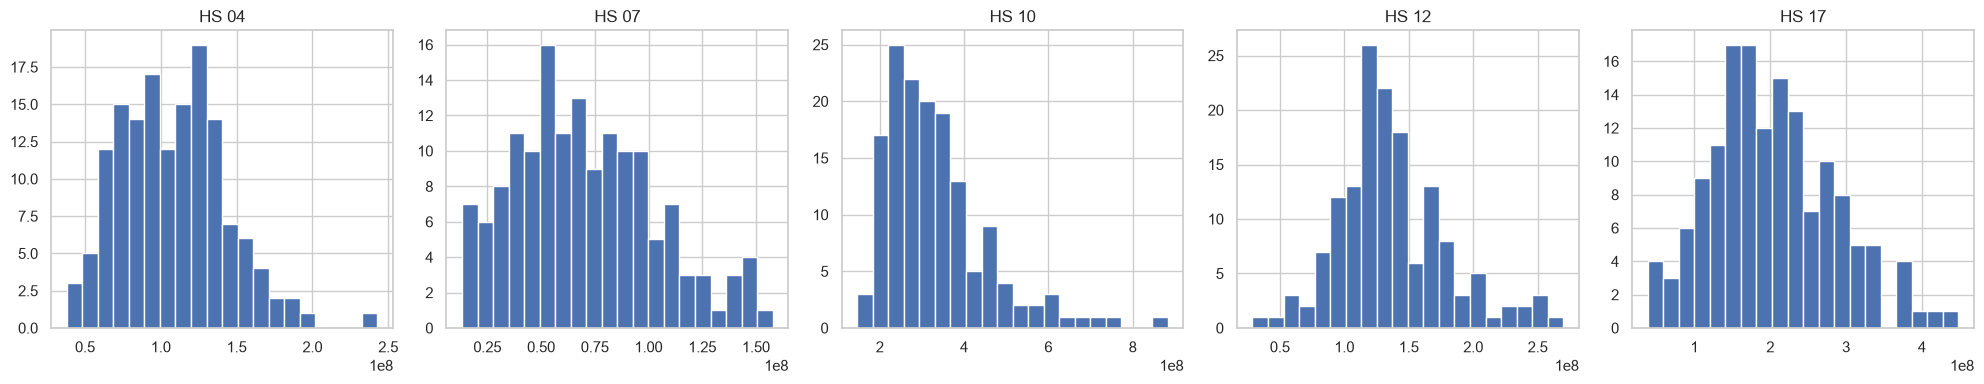

In [473]:
# Visualize the distribution of import values for each HS code
hs_list = sorted(df['HS_Code'].unique())
fig, axes = plt.subplots(1, len(hs_list), figsize=(20,4))

for ax, hs in zip(axes, hs_list):
    data_hs = df[df['HS_Code']==hs]['Import_Value']
    ax.hist(data_hs, bins=20)
    ax.set_title(f'HS {hs}')

plt.tight_layout()
plt.show()

* All commodities are right-skewed to varying degrees
* HS 10 has a high skewness of 1.54, far above other commodities, kurtosis of 3.27 also indicates the potential for outliers that pull the distribution to the right. Therefore, HS 10 is a strong candidate for a log-transform that can help stabilize the distribution before modeling

### Data Quality Check

In [474]:
# Check for missing values in the dataset
df.isna().sum()

Period          0
HS_Code         0
Import_Value    0
dtype: int64

In [475]:
# Check for duplicates
df.duplicated(subset=['Period','HS_Code']).sum()

np.int64(0)

In [476]:
# Check for missing periods for each HS code
expected_periods = pd.date_range(start='2014-01-01', end='2026-05-01', freq='MS')
for hs in df['HS_Code'].unique():
    actual_periods = set(df[df['HS_Code'] == hs]['Period'])
    missing = set(expected_periods) - actual_periods
    if missing:
        print(f"HS {hs} — missing periods: {sorted(missing)}")
    else:
        print(f"HS {hs} — complete, no gaps")

HS 04 — complete, no gaps
HS 07 — complete, no gaps
HS 10 — complete, no gaps
HS 12 — complete, no gaps
HS 17 — complete, no gaps


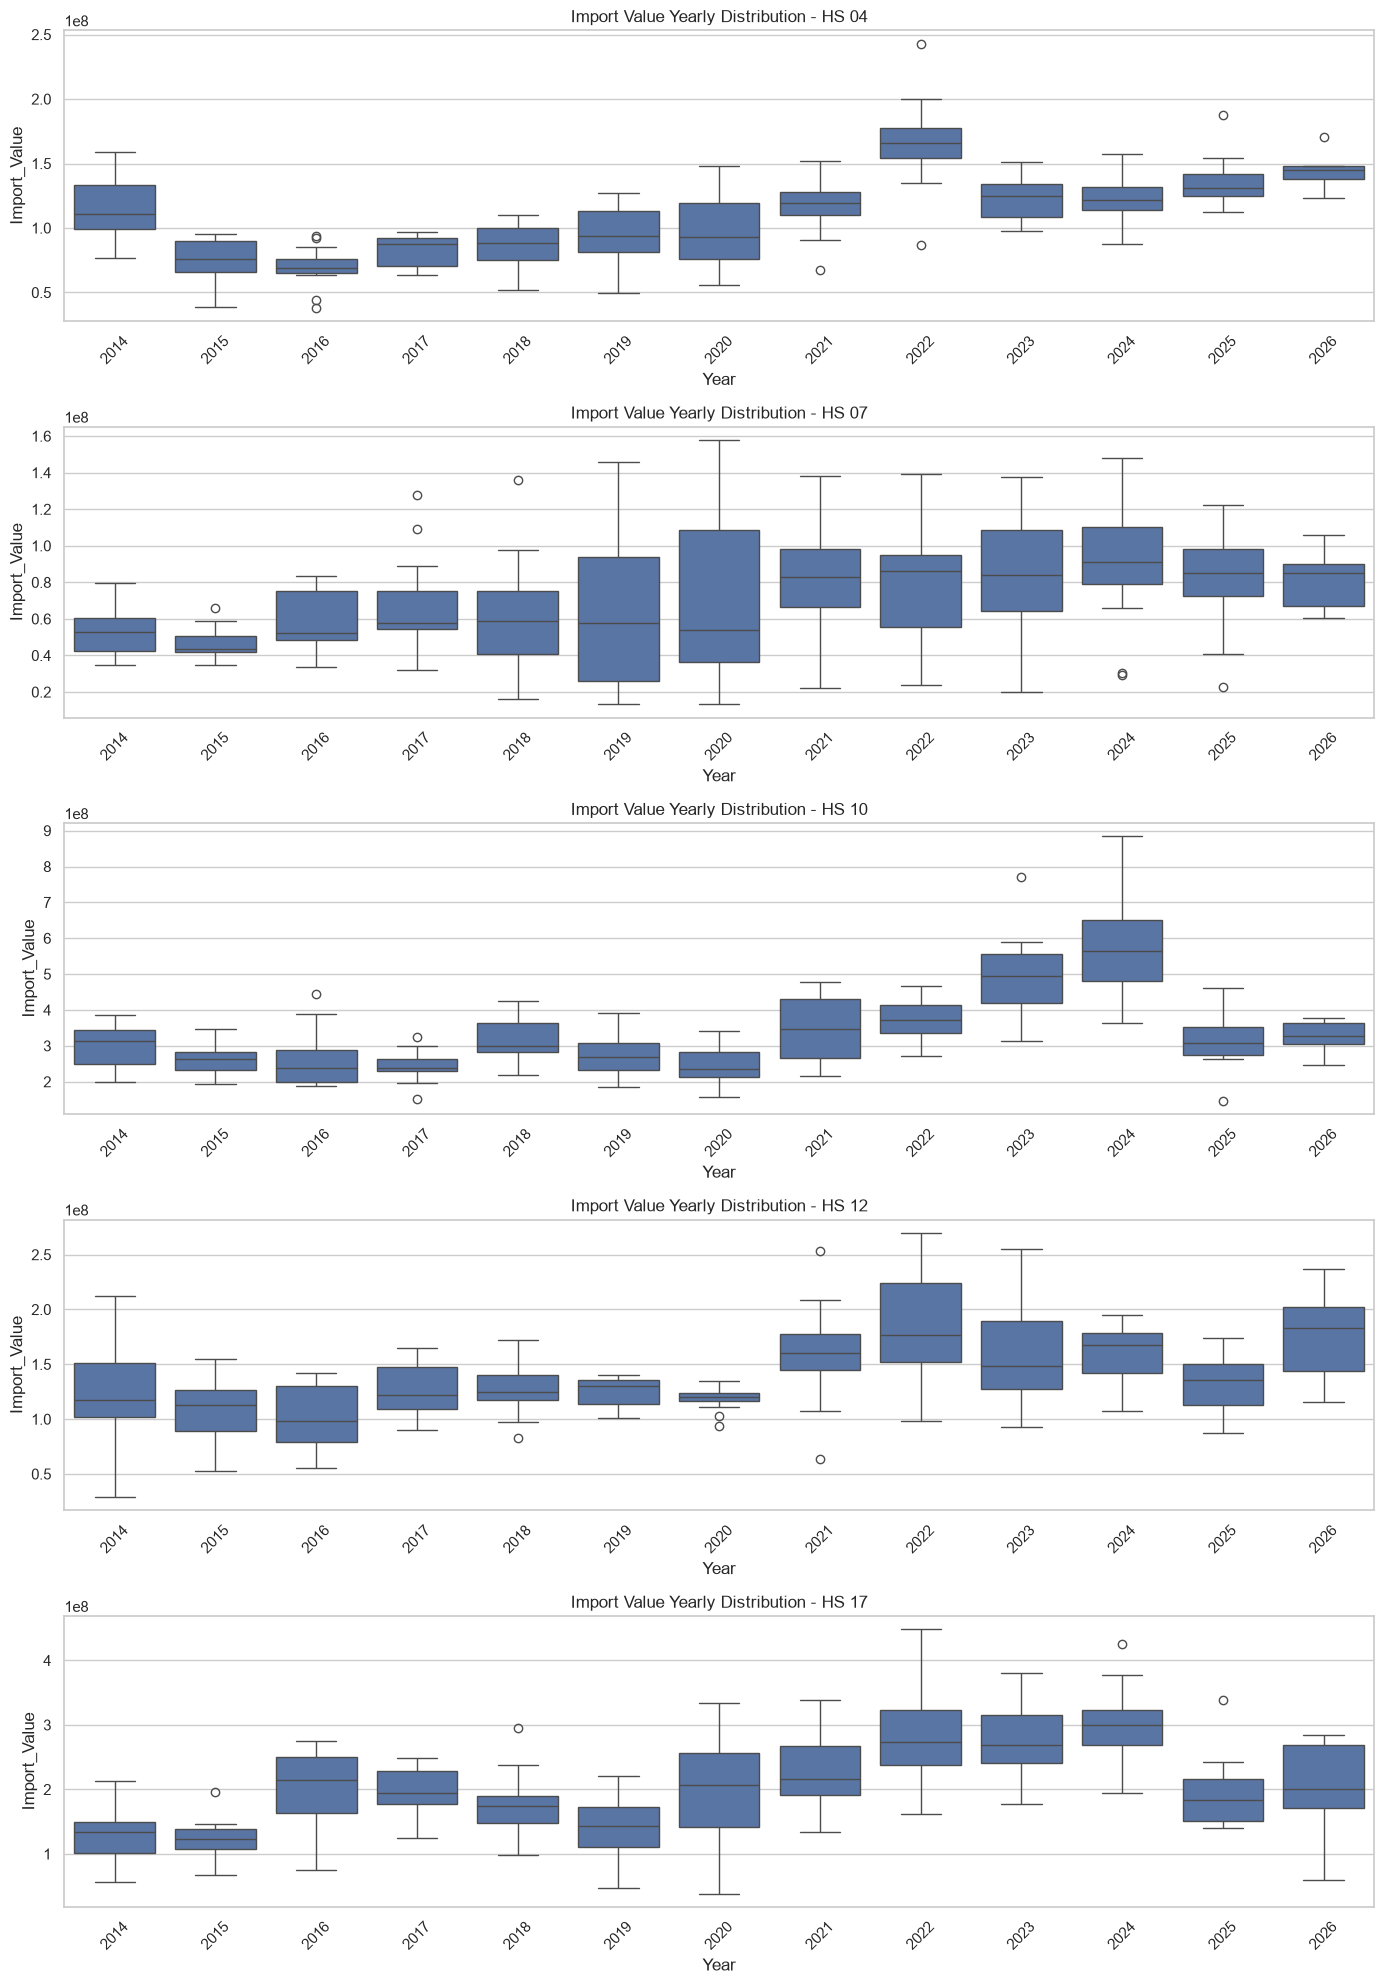

In [477]:
# Check outliers using boxplots
df['Year'] = df['Period'].dt.year
hs_list = df['HS_Code'].unique()
fig, axes = plt.subplots(len(hs_list), 1, figsize=(14, 4*len(hs_list)))

for ax, hs in zip(axes, hs_list):
    data_hs = df[df['HS_Code'] == hs]
    sns.boxplot(data=data_hs, x='Year', y='Import_Value', ax=ax)
    ax.set_title(f'Import Value Yearly Distribution - HS {hs}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Exploratory Data Analysis

#### Import Value Trend

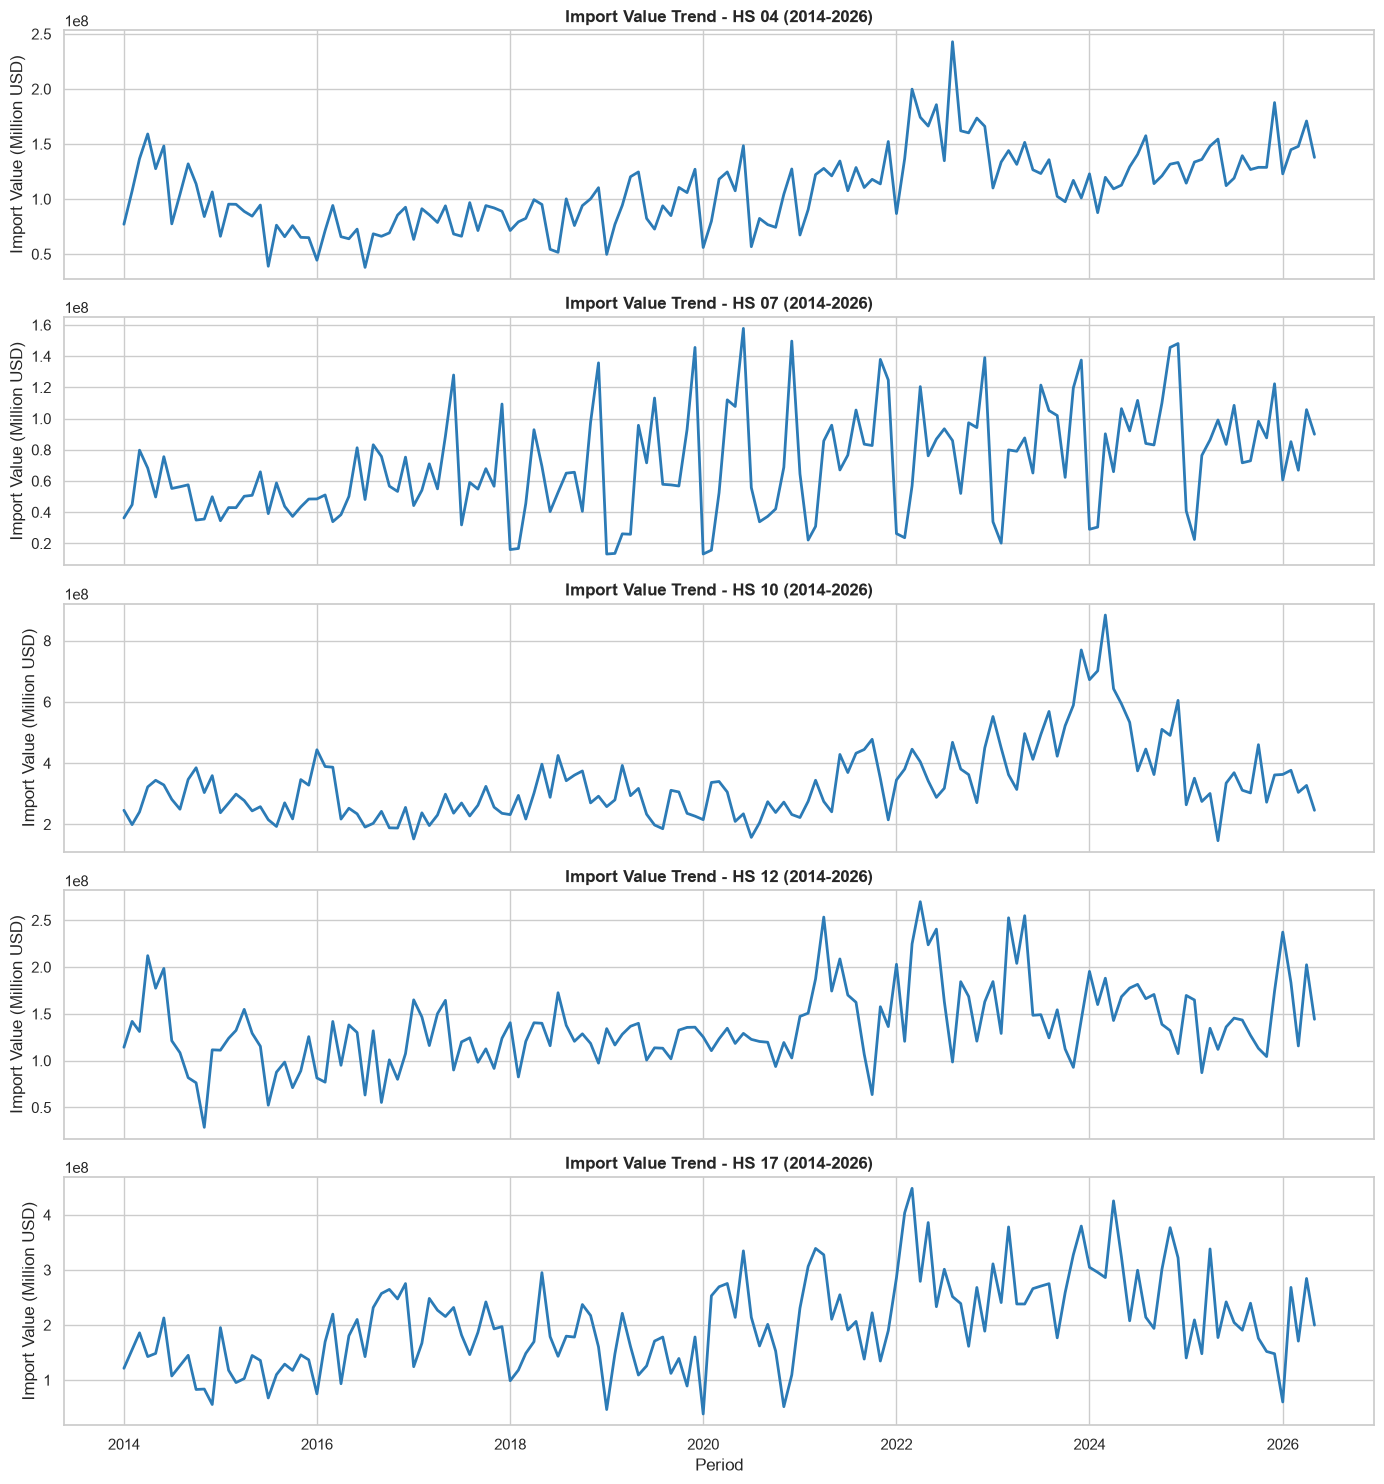

In [478]:
# Visualize the trend of import values over time for each HS code
df = df.sort_values(by=['HS_Code', 'Period'])

sns.set_theme(style="whitegrid")
hs_list = sorted(df['HS_Code'].unique())

# Individual Subplots
# sharex=True aligns the x-axis timeline perfectly across all plots
fig, axes = plt.subplots(len(hs_list), 1, figsize=(14, 3 * len(hs_list)), sharex=True)

for ax, hs in zip(axes, hs_list):
    data_hs = df[df['HS_Code'] == hs]

    # Plot the line chart for each specific HS code
    sns.lineplot(data=data_hs, x='Period', y='Import_Value', ax=ax, linewidth=2, color='#2c7bb6')

    # Formatting for professional appearance
    ax.set_title(f'Import Value Trend - HS {hs} (2014-2026)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Import Value (Million USD)')
    ax.set_xlabel('Period')

plt.tight_layout()
plt.show()

From the line plot, it can be seen that the import value data is non-stationary because it does not have a constant mean and variance over time. Classical linear models require differencing to stabilize the data. This line plot indicates a pattern of seasonality and cyclicality.

#### Year-over-Year Growth Rate

In [479]:
# Year-over-Year Growth Rate
# Import value per year per commodity
yearly = df.groupby(['HS_Code','Year'])['Import_Value'].sum().reset_index()

# Growth rate per komoditas
yearly['YoY_Growth_%'] = yearly.groupby('HS_Code')['Import_Value'].pct_change() * 100
yearly = yearly[yearly['Year'] < 2026]

pd.set_option('display.max_rows', None)
yearly

,HS_Code,Year,Import_Value,YoY_Growth_%
0,04,2014,1.374223e+09,NaN
1,04,2015,9.117069e+08,-33.656567
2,04,2016,8.324027e+08,-8.698422
3,04,2017,9.905174e+08,18.994976
4,04,2018,1.014479e+09,2.419119
5,04,2019,1.143428e+09,12.710815
6,04,2020,1.156623e+09,1.154031
7,04,2021,1.394290e+09,20.548316
8,04,2022,1.989220e+09,42.669021
9,04,2023,1.474328e+09,-25.884109


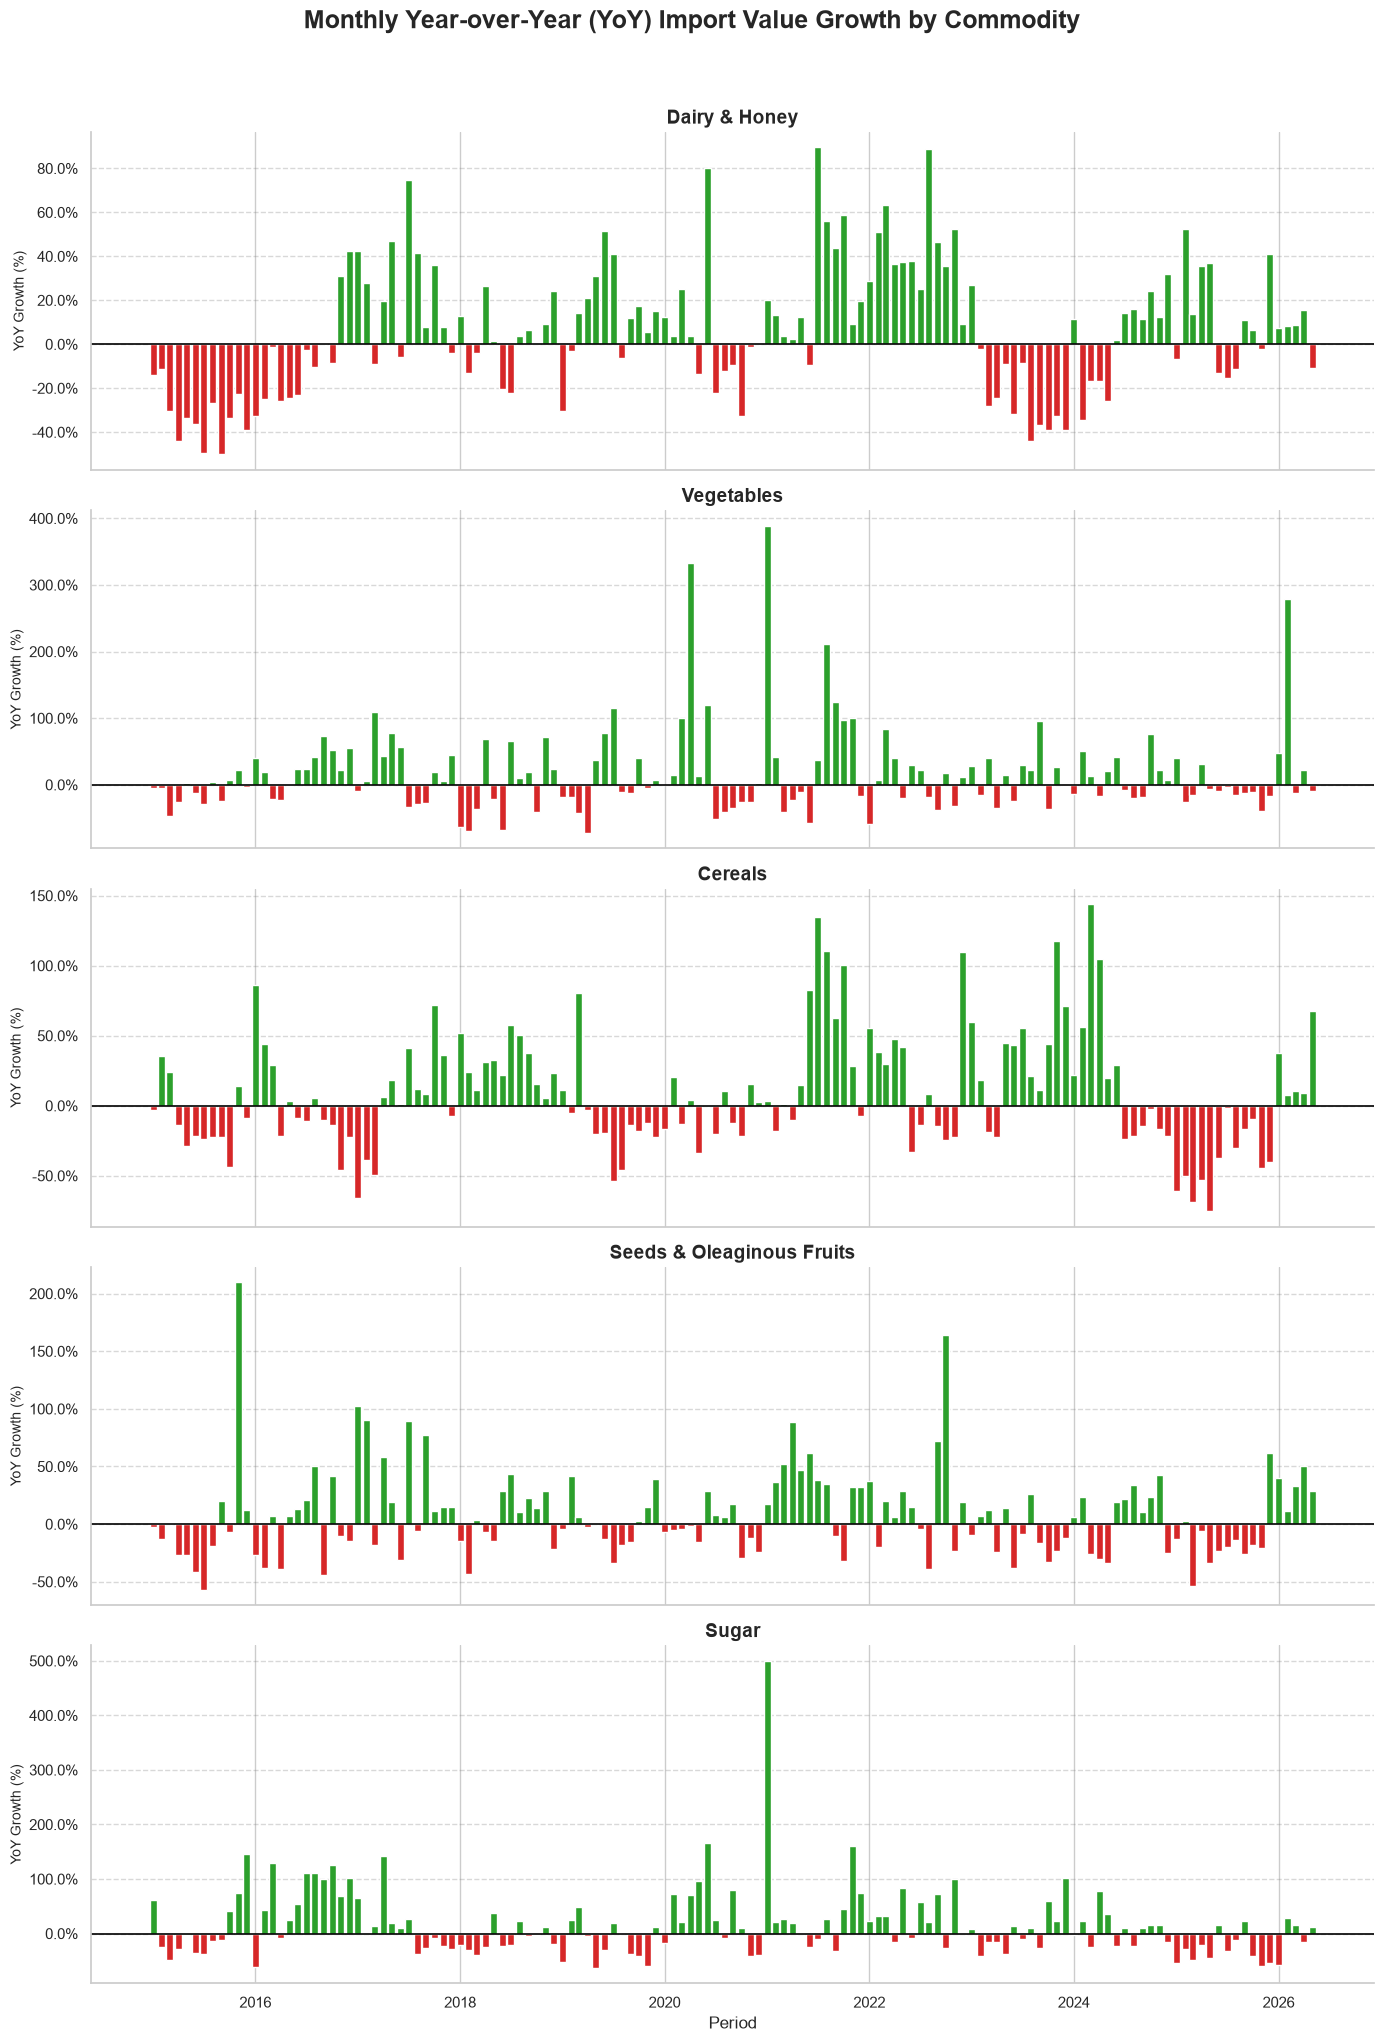

In [480]:
# Calculate YoY exactly as Streamlit does
# Ensure data is sorted chronologically per commodity before calculating pct_change
df_sorted = df.sort_values(by=['HS_Code', 'Period']).copy()
df_sorted['YoY_Growth_%'] = df_sorted.groupby('HS_Code')['Import_Value'].pct_change(periods=12) * 100

# Map HS Codes to readable names
hs_mapping = {
    '04': 'Dairy & Honey',
    '07': 'Vegetables',
    '10': 'Cereals',
    '12': 'Seeds & Oleaginous Fruits',
    '17': 'Sugar'
}
df_sorted['Commodity'] = df_sorted['HS_Code'].map(hs_mapping)

# Setup the Subplots Grid (5 rows, 1 column)
commodities = list(hs_mapping.values())
fig, axes = plt.subplots(5, 1, figsize=(14, 20), sharex=True)

# Iterate through each commodity and plot its own bar chart
for i, commodity in enumerate(commodities):
    ax = axes[i]
    
    # Filter for the specific commodity and drop the first 12 months (which are NaN)
    df_single = df_sorted[df_sorted['Commodity'] == commodity]
    
    # Apply Streamlit's Green/Red conditional coloring logic
    bar_colors = ['#2ca02c' if val >= 0 else '#d62728' for val in df_single['YoY_Growth_%']]
    
    # Plot the monthly bars
    ax.bar(df_single['Period'], df_single['YoY_Growth_%'], color=bar_colors, width=25)
    
    # Styling for each subplot
    ax.axhline(0, color='black', linewidth=1.2, linestyle='-')
    ax.set_title(f'{commodity}', fontsize=14, fontweight='bold')
    ax.set_ylabel('YoY Growth (%)', fontsize=10)
    
    # Format Y-axis to percentages
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:,.1f}%'))
    
    # Add background gridlines
    ax.set_axisbelow(True)
    ax.yaxis.grid(color='gray', linestyle='dashed', alpha=0.3)

# Layout Adjustments
plt.xlabel('Period', fontsize=12)
sns.despine()

plt.suptitle('Monthly Year-over-Year (YoY) Import Value Growth by Commodity', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

The graph shows high volatility (rapid ups and downs over a wide range in a short time). This shows that the value of imports is vulnerable to macroeconomic shocks (events or sudden changes that affect the economy), so that classical statistical models often have difficulty making predictions.

## Data Preparation 2

### Split Data Train and Test

In [481]:
# Split data training dan data testing
train_df = df[df['Period'] <= '2025-05-01'].copy()
test_df = df[df['Period'] > '2025-05-01'].copy()

In [482]:
train_df.tail()

,Period,HS_Code,Import_Value,Year
756,2025-01-01,17,1.402446e+08,2025
757,2025-02-01,17,2.092892e+08,2025
758,2025-03-01,17,1.479223e+08,2025
759,2025-04-01,17,3.381631e+08,2025
760,2025-05-01,17,1.772675e+08,2025


In [483]:
test_df.count()

Period          60
HS_Code         60
Import_Value    60
Year            60
dtype: int64

In [484]:
print("=== TRAINING SET ===")
print("Period:", train_df['Period'].min(), "-", train_df['Period'].max())
print("Total observations:", len(train_df))
print(train_df.groupby('HS_Code').size())

print("\n=== TESTING SET ===")
print("Period:", test_df['Period'].min(), "-", test_df['Period'].max())
print("Total observations:", len(test_df))
print(test_df.groupby('HS_Code').size())

=== TRAINING SET ===
Period: 2014-01-01 00:00:00 - 2025-05-01 00:00:00
Total observations: 685
HS_Code
04    137
07    137
10    137
12    137
17    137
dtype: int64

=== TESTING SET ===
Period: 2025-06-01 00:00:00 - 2026-05-01 00:00:00
Total observations: 60
HS_Code
04    12
07    12
10    12
12    12
17    12
dtype: int64


### Log Transform

In [485]:
# Create a copy of training data for log transformation
train_df = train_df.copy()

# Apply log transformation
train_df['Log_Import_Value'] = np.log(train_df['Import_Value'])

# Check results
train_df.head()

,Period,HS_Code,Import_Value,Year,Log_Import_Value
0,2014-01-01,04,77115100.0,2014,18.160810
1,2014-02-01,04,107389161.0,2014,18.491970
2,2014-03-01,04,136648208.0,2014,18.732920
3,2014-04-01,04,159130719.0,2014,18.885237
4,2014-05-01,04,127602341.0,2014,18.664429


In [486]:
print("Minimum Import Value:", train_df['Import_Value'].min())
print("Zero values:", (train_df['Import_Value'] == 0).sum())
print("Negative values:", (train_df['Import_Value'] < 0).sum())

Minimum Import Value: 13196510.0
Zero values: 0
Negative values: 0


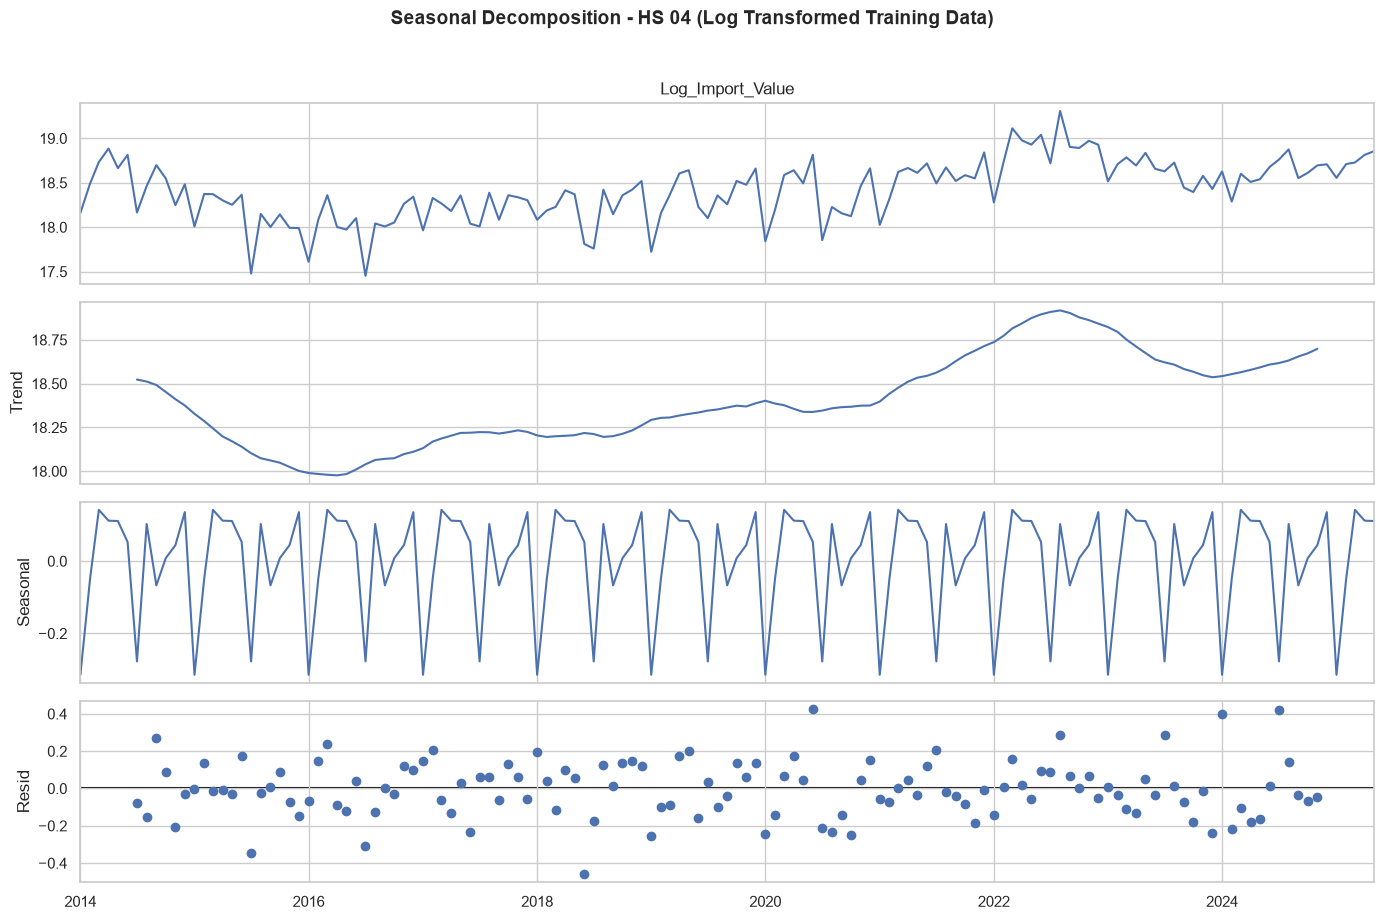

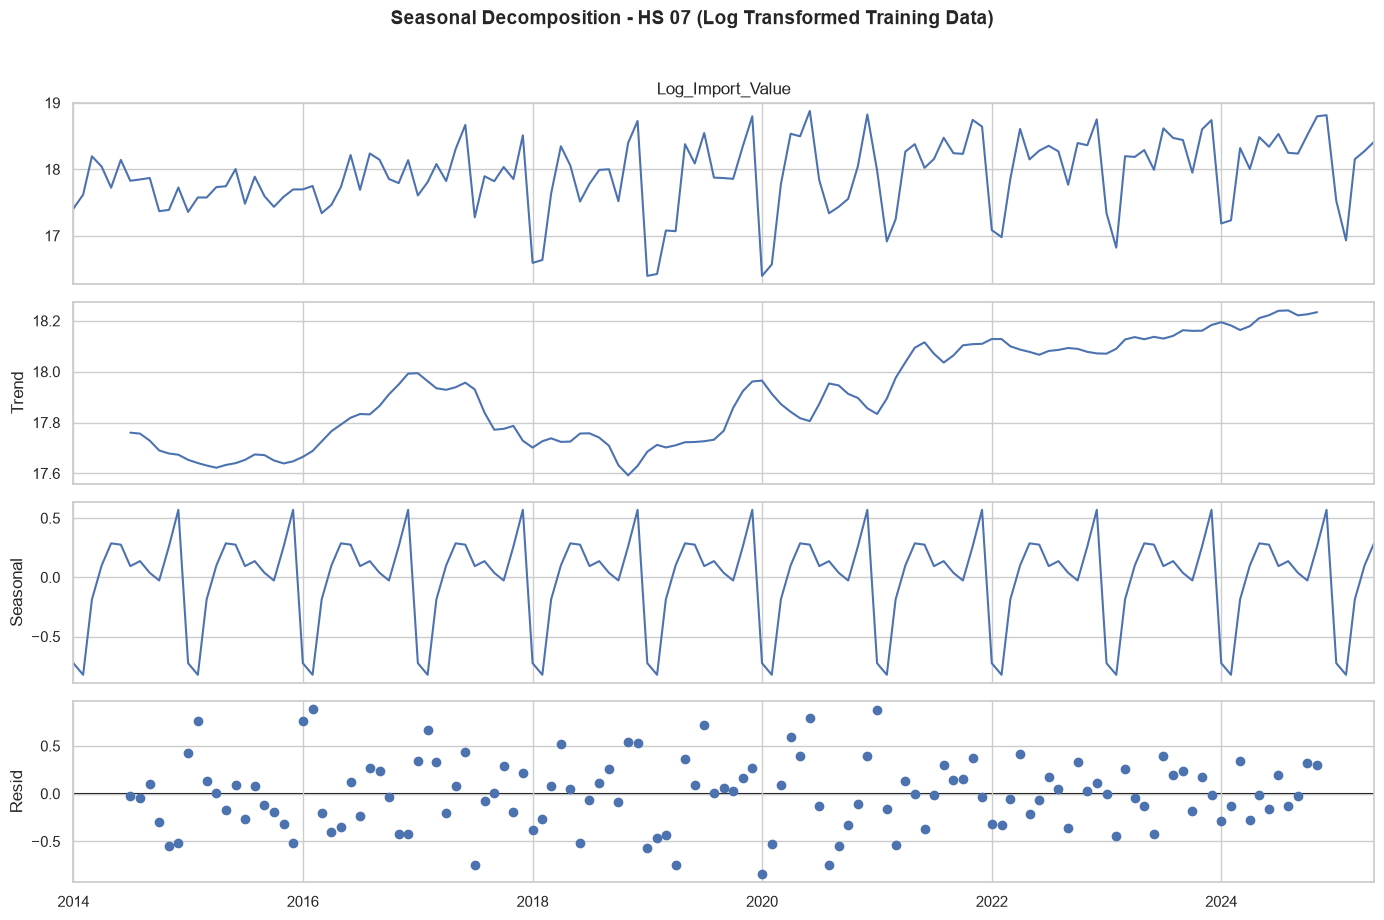

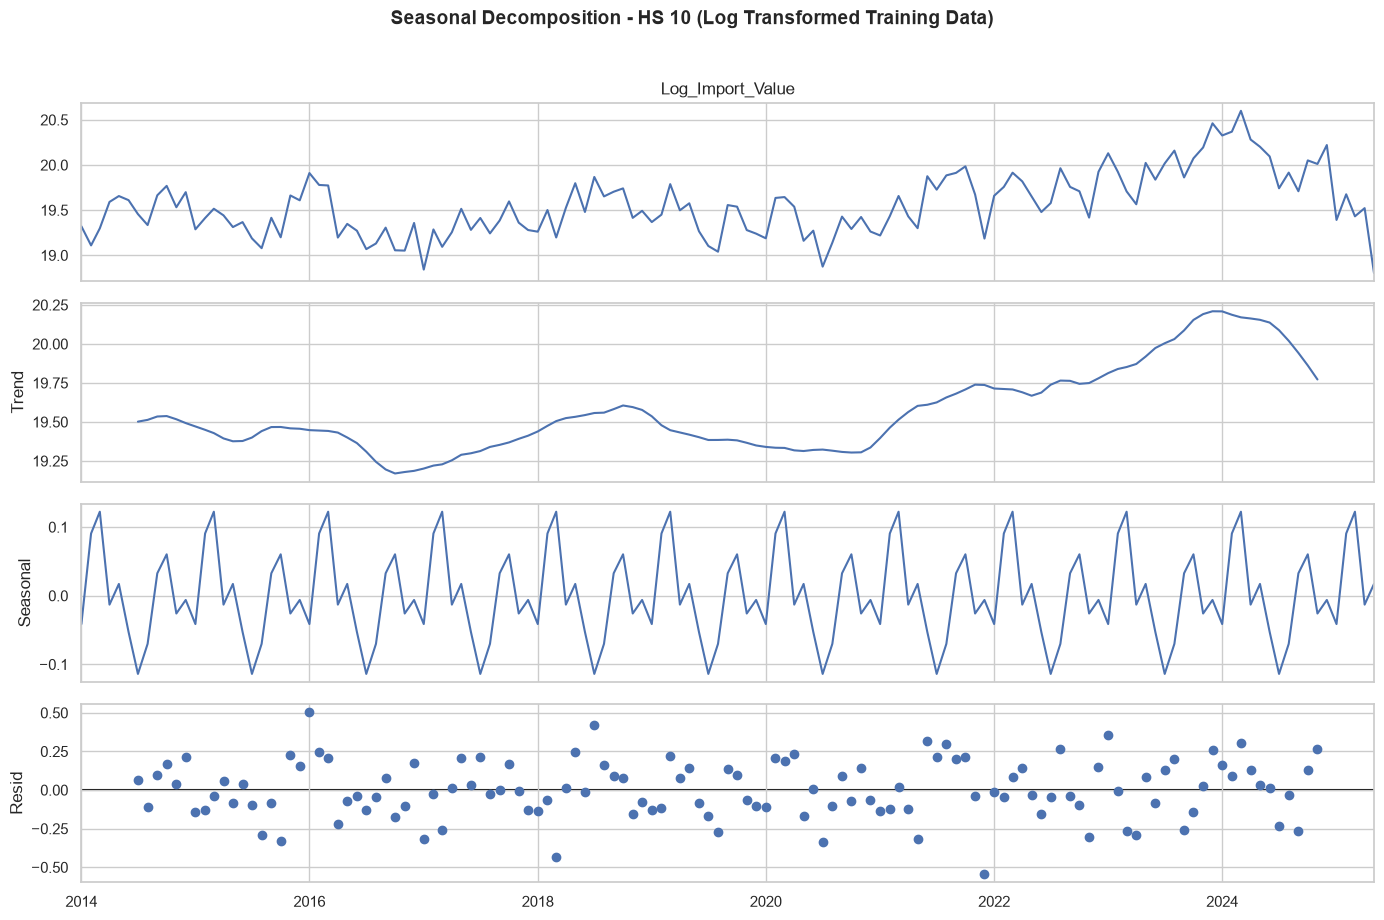

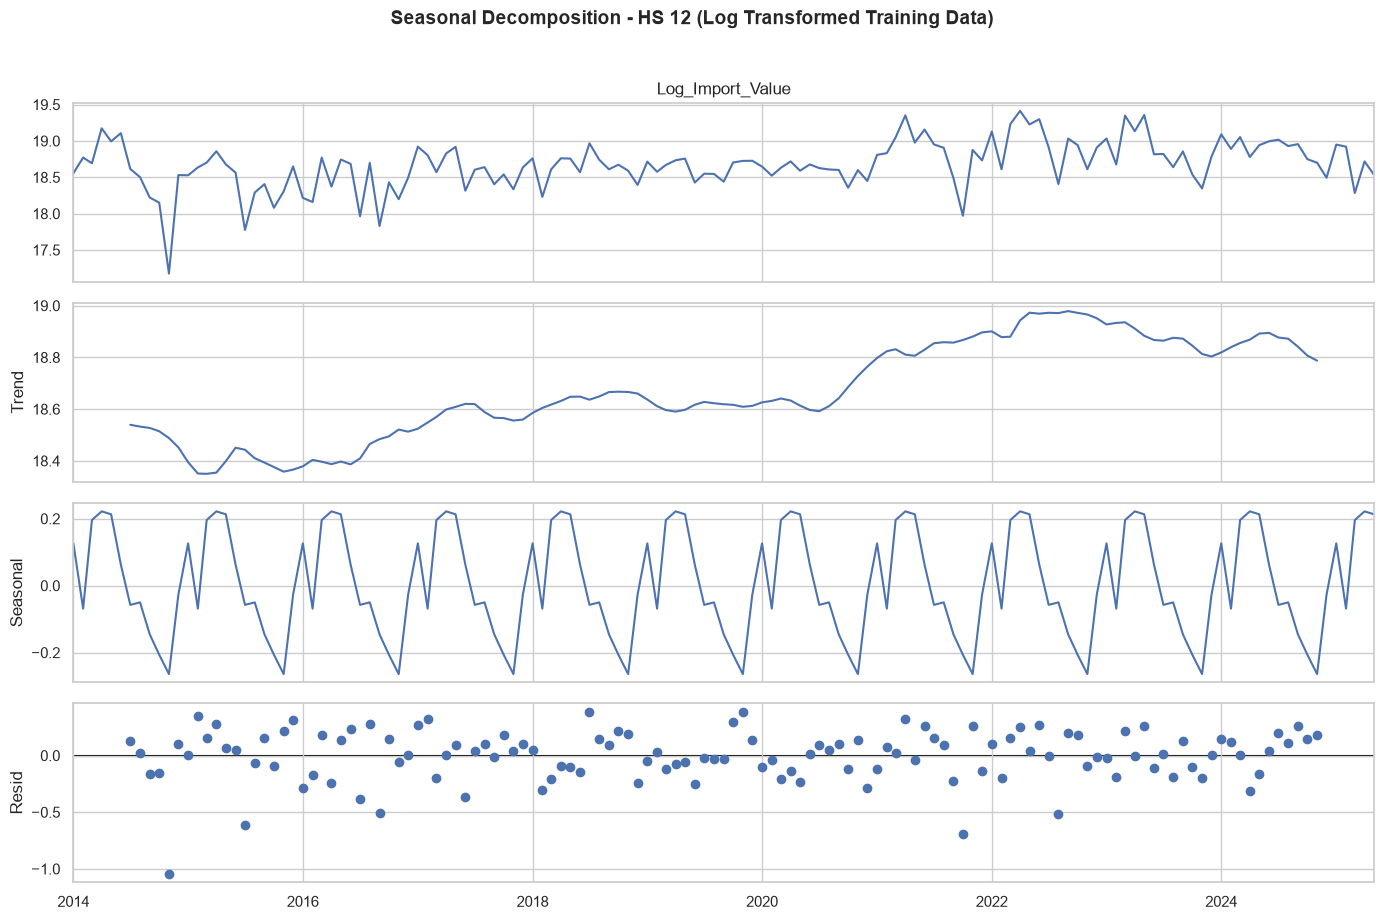

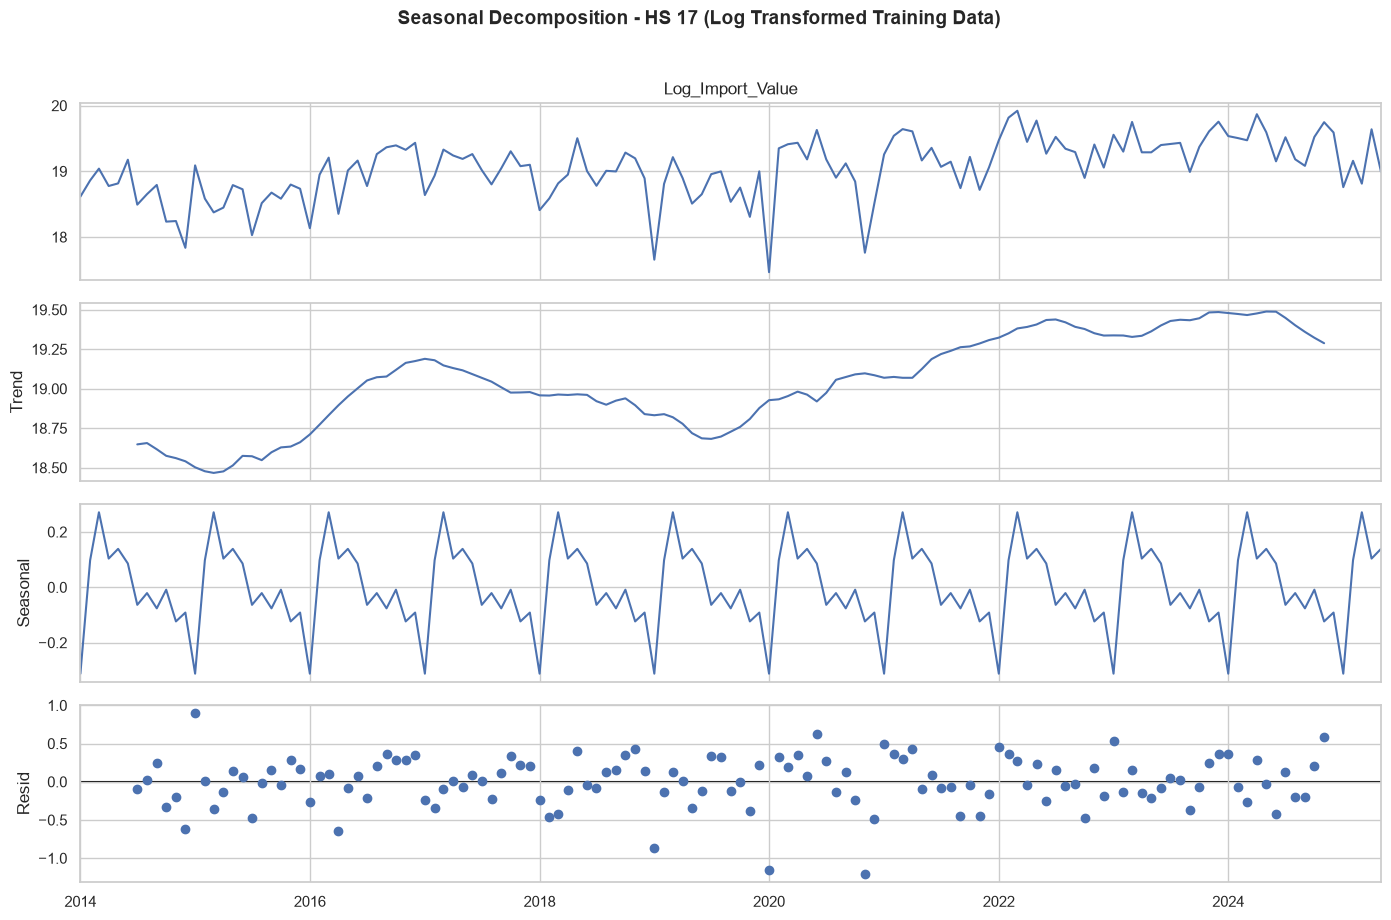

In [487]:
hs_list = sorted(train_df['HS_Code'].unique())

for hs in hs_list:

    data_hs = train_df[
        train_df['HS_Code'] == hs
    ].sort_values('Period').copy()

    ts = data_hs.set_index('Period')['Log_Import_Value']

    # Seasonal decomposition
    decomposition = seasonal_decompose(
        ts,
        model='additive',
        period=12
    )

    # Visualization
    fig = decomposition.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle(
        f'Seasonal Decomposition - HS {hs} (Log Transformed Training Data)',
        fontsize=14,
        fontweight='bold',
        y=1.02
    )

    plt.tight_layout()
    plt.show()

In [488]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd

# Initialize a list to store the formal results for your journal table
adf_results = []
hs_list = sorted(train_df['HS_Code'].unique())\

for hs in hs_list:
    # Extract the time series for the specific commodity
    data_hs = train_df[train_df['HS_Code'] == hs]['Log_Import_Value'].dropna()

    # Run ADF on the original raw data (d = 0)
    result_raw = adfuller(data_hs)
    p_val_raw = result_raw[1]

    # Check if the raw data is already stationary (p-value < 0.05)
    if p_val_raw < 0.05:
        d = 0
        status = "Stationer (Level 0)"
    else:
        # Apply 1st order differencing (d = 1)
        data_diff1 = data_hs.diff().dropna()
        result_diff1 = adfuller(data_diff1)
        p_val_diff1 = result_diff1[1]

        if p_val_diff1 < 0.05:
            d = 1
            status = "Stationer (Differencing 1)"
        else:
            # Apply 2nd order differencing (d = 2)
            # It is extremely rare for economic data to need more than d=2
            data_diff2 = data_diff1.diff().dropna()
            result_diff2 = adfuller(data_diff2)
            p_val_diff2 = result_diff2[1]

            d = 2
            status = "Stationer (Differencing 2)"

    # Save the results for this commodity
    adf_results.append({
        'Kode HS': hs,
        'P-Value (Data Asli)': f"{p_val_raw:.4f}",
        'Ordo Differencing (d)': d,
        'P-Value Differencing 1': f"{p_val_diff1:.4f}",
        'P-Value Differencing 2': f"{p_val_diff2:.4f}",
        'Kesimpulan': status
    })

# Convert the results into a clean Pandas DataFrame
df_adf_summary = pd.DataFrame(adf_results)
print(df_adf_summary.to_string(index=False))

Kode HS P-Value (Data Asli)  Ordo Differencing (d) P-Value Differencing 1 P-Value Differencing 2                 Kesimpulan
     04              0.6010                      2                 0.0738                 0.0000 Stationer (Differencing 2)
     07              0.8206                      1                 0.0000                 0.0000 Stationer (Differencing 1)
     10              0.0170                      0                 0.0000                 0.0000        Stationer (Level 0)
     12              0.6862                      1                 0.0000                 0.0000 Stationer (Differencing 1)
     17              0.3591                      1                 0.0043                 0.0000 Stationer (Differencing 1)


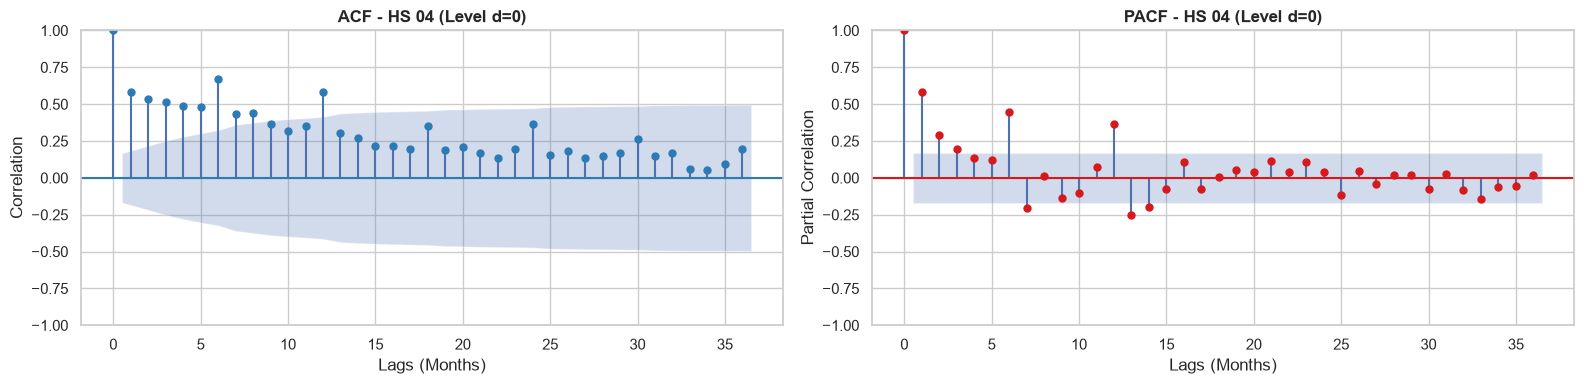

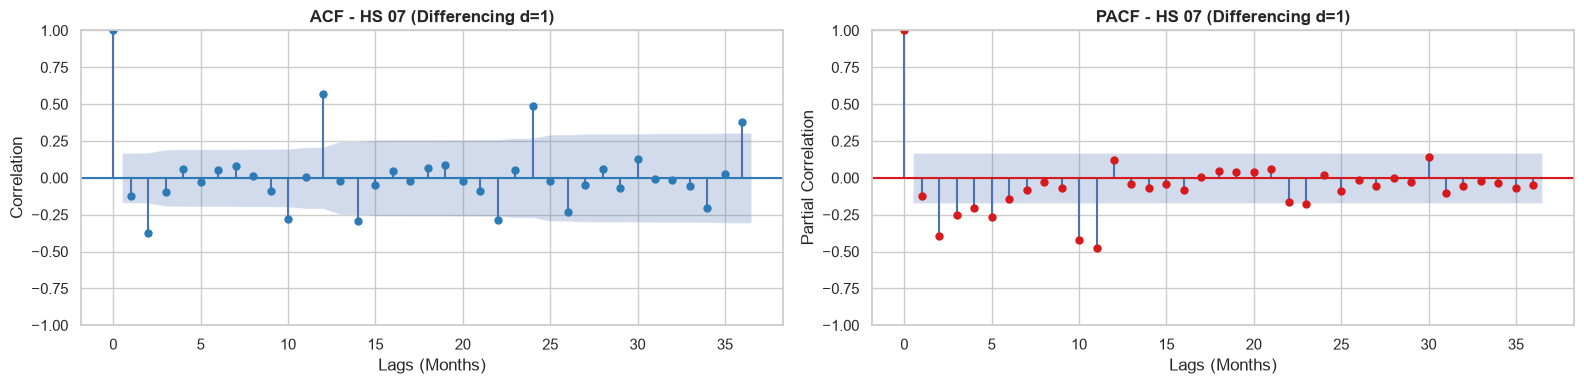

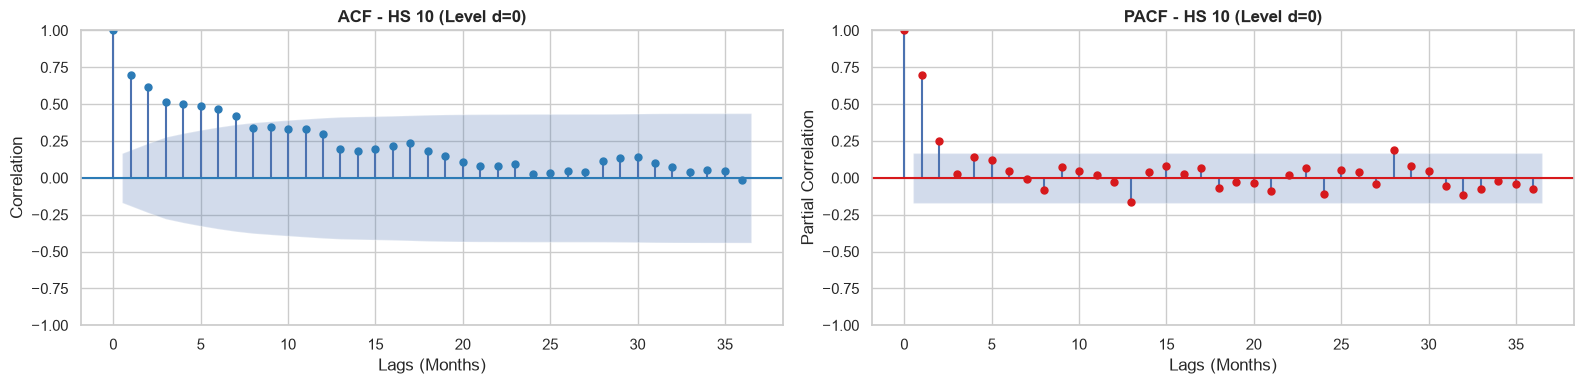

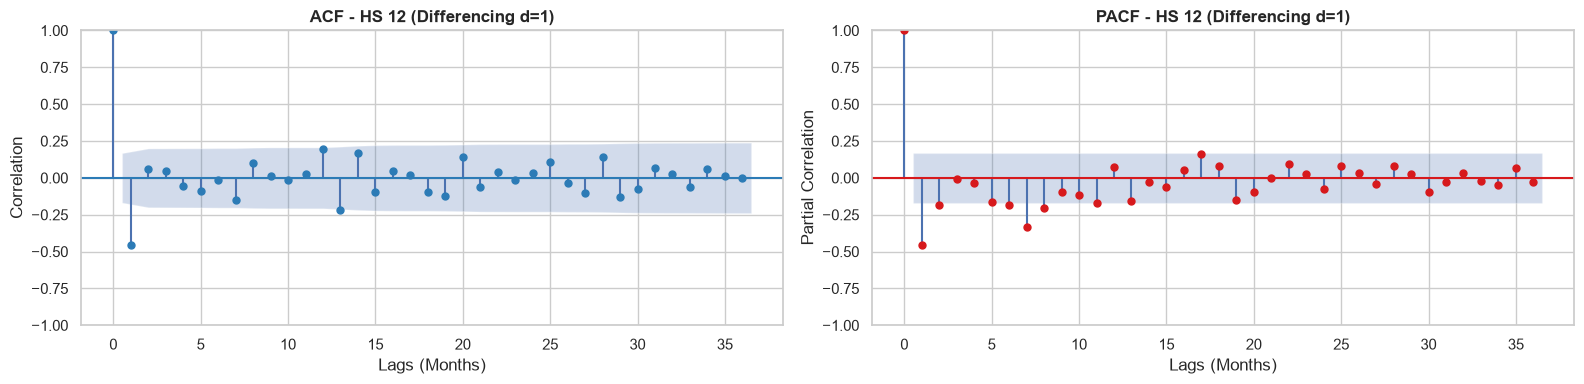

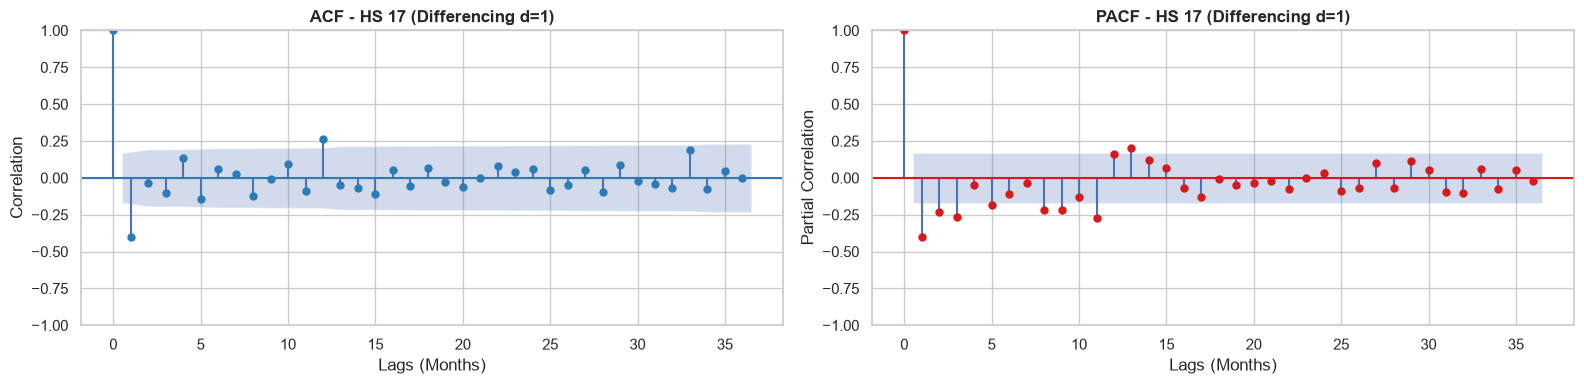

In [489]:
# Define the differencing order (d) based on your ADF test results
d_orders = {'04': 2, '07': 1, '10': 0, '12': 1, '17': 1}
hs_list = sorted(train_df['HS_Code'].unique())

for hs in hs_list:
    # Extract the time series for the specific commodity
    data_hs = train_df[train_df['HS_Code'] == hs].set_index('Period')['Log_Import_Value']

    # Apply the correct differencing dynamically
    d = d_orders[hs]
    if d == 1:
        data_stationary = data_hs.diff().dropna()
        title_suffix = "(Differencing d=1)"
    else:
        data_stationary = data_hs.dropna()
        title_suffix = "(Level d=0)"

    # Create subplots: 1 row, 2 columns
    fig, axes = plt.subplots(1, 2, figsize=(16, 4))

    # Generate ACF Plot (determines 'q' and 'Q')
    # lags=36 allows us to see 3 full years of seasonality (12, 24, 36)
    plot_acf(data_stationary, lags=36, ax=axes[0], color='#2c7bb6')
    axes[0].set_title(f'ACF - HS {hs} {title_suffix}', fontweight='bold')
    axes[0].set_xlabel('Lags (Months)')
    axes[0].set_ylabel('Correlation')

    # Generate PACF Plot (determines 'p' and 'P')
    plot_pacf(data_stationary, lags=36, ax=axes[1], color='#d7191c', method='ywm')
    axes[1].set_title(f'PACF - HS {hs} {title_suffix}', fontweight='bold')
    axes[1].set_xlabel('Lags (Months)')
    axes[1].set_ylabel('Partial Correlation')

    plt.tight_layout()
    plt.show()

## Modeling

### Time Series Cross Validation with 2 fold, horizon 12 bulan

In [397]:
def create_time_series_folds(data):
    """
    Membuat 2 expanding-window folds untuk setiap HS Code.
    Transformasi log hanya diterapkan pada data training masing-masing fold.
    Data validasi tetap pada skala asli.
    """

    fold_periods = [
        {
            'fold': 1,
            'train_end': '2023-05-01',
            'val_start': '2023-06-01',
            'val_end': '2024-05-01'
        },
        {
            'fold': 2,
            'train_end': '2024-05-01',
            'val_start': '2024-06-01',
            'val_end': '2025-05-01'
        }
    ]

    folds = []

    for period in fold_periods:

        fold_train_list = []
        fold_val_list = []

        for hs in sorted(data['HS_Code'].unique()):

            data_hs = (
                data[data['HS_Code'] == hs]
                .sort_values('Period')
                .copy()
            )

            # Pisahkan training dan validation
            train_fold = data_hs[
                data_hs['Period'] <= pd.Timestamp(period['train_end'])
            ].copy()

            val_fold = data_hs[
                (data_hs['Period'] >= pd.Timestamp(period['val_start'])) &
                (data_hs['Period'] <= pd.Timestamp(period['val_end']))
            ].copy()

            # Pastikan panjang data sesuai rancangan
            expected_train = 113 if period['fold'] == 1 else 125

            assert len(train_fold) == expected_train, (
                f"Jumlah training tidak sesuai untuk HS {hs}, Fold {period['fold']}"
            )

            assert len(val_fold) == 12, (
                f"Jumlah validasi tidak sesuai untuk HS {hs}, Fold {period['fold']}"
            )

            # Pastikan tidak ada nilai nol atau negatif
            assert (train_fold['Import_Value'] > 0).all()
            assert (val_fold['Import_Value'] > 0).all()

            # Transformasi log pada training fold saja
            train_fold['Log_Import_Value'] = np.log(
                train_fold['Import_Value']
            )

            # Validasi dipertahankan pada skala asli
            fold_train_list.append(train_fold)
            fold_val_list.append(val_fold)

        folds.append({
            'fold': period['fold'],
            'train': pd.concat(
                fold_train_list, ignore_index=True
            ),
            'validation': pd.concat(
                fold_val_list, ignore_index=True
            )
        })

    return folds

In [398]:
folds = create_time_series_folds(train_df)

for fold in folds:

    print(f"\n{'='*50}")
    print(f"FOLD {fold['fold']}")
    print(f"{'='*50}")

    train_fold = fold['train']
    val_fold = fold['validation']

    print("\nTraining:")
    print("Jumlah observasi:", len(train_fold))
    print("Periode:", train_fold['Period'].min(),
          "sampai", train_fold['Period'].max())

    print("\nValidation:")
    print("Jumlah observasi:", len(val_fold))
    print("Periode:", val_fold['Period'].min(),
          "sampai", val_fold['Period'].max())

    print("\nJumlah observasi per HS - Training:")
    print(train_fold.groupby('HS_Code').size())

    print("\nJumlah observasi per HS - Validation:")
    print(val_fold.groupby('HS_Code').size())


FOLD 1

Training:
Jumlah observasi: 565
Periode: 2014-01-01 00:00:00 sampai 2023-05-01 00:00:00

Validation:
Jumlah observasi: 60
Periode: 2023-06-01 00:00:00 sampai 2024-05-01 00:00:00

Jumlah observasi per HS - Training:
HS_Code
04    113
07    113
10    113
12    113
17    113
dtype: int64

Jumlah observasi per HS - Validation:
HS_Code
04    12
07    12
10    12
12    12
17    12
dtype: int64

FOLD 2

Training:
Jumlah observasi: 625
Periode: 2014-01-01 00:00:00 sampai 2024-05-01 00:00:00

Validation:
Jumlah observasi: 60
Periode: 2024-06-01 00:00:00 sampai 2025-05-01 00:00:00

Jumlah observasi per HS - Training:
HS_Code
04    125
07    125
10    125
12    125
17    125
dtype: int64

Jumlah observasi per HS - Validation:
HS_Code
04    12
07    12
10    12
12    12
17    12
dtype: int64


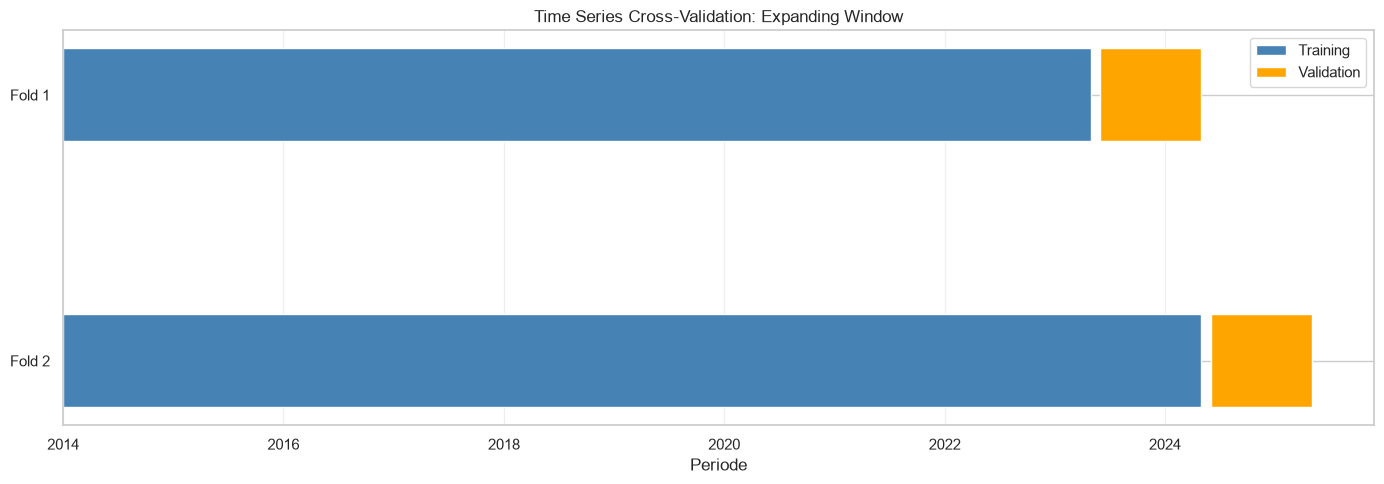

In [399]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

fold_colors = {
    'Training': 'steelblue',
    'Validation': 'orange'
}

fold_info = [
    {
        'name': 'Fold 1',
        'train_start': pd.Timestamp('2014-01-01'),
        'train_end': pd.Timestamp('2023-05-01'),
        'val_start': pd.Timestamp('2023-06-01'),
        'val_end': pd.Timestamp('2024-05-01'),
        'y': 2
    },
    {
        'name': 'Fold 2',
        'train_start': pd.Timestamp('2014-01-01'),
        'train_end': pd.Timestamp('2024-05-01'),
        'val_start': pd.Timestamp('2024-06-01'),
        'val_end': pd.Timestamp('2025-05-01'),
        'y': 1
    }
]

for item in fold_info:

    ax.barh(
        item['y'],
        (item['train_end'] - item['train_start']).days,
        left=item['train_start'],
        height=0.35,
        color=fold_colors['Training'],
        label='Training' if item['y'] == 2 else ''
    )

    ax.barh(
        item['y'],
        (item['val_end'] - item['val_start']).days,
        left=item['val_start'],
        height=0.35,
        color=fold_colors['Validation'],
        label='Validation' if item['y'] == 2 else ''
    )

ax.set_yticks([1, 2])
ax.set_yticklabels(['Fold 2', 'Fold 1'])
ax.set_title('Time Series Cross-Validation: Expanding Window')
ax.set_xlabel('Periode')
ax.legend()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [400]:
def inverse_log_transform(predictions):
    """
    Mengembalikan prediksi dari skala log ke skala asli.
    """
    return np.exp(predictions)

### SARIMA

In [401]:
from itertools import product

# Non-seasonal parameters
p_values = [0, 1, 2]
d_values = [0, 1]
q_values = [0, 1, 2]

# Seasonal parameters
P_values = [0, 1]
D_values = [0, 1]
Q_values = [0, 1]

# Seasonal period
seasonal_period = 12

# Generate all combinations
sarima_grid = []

for p, d, q in product(p_values, d_values, q_values):
    for P, D, Q in product(P_values, D_values, Q_values):

        sarima_grid.append({
            'order': (p, d, q),
            'seasonal_order': (P, D, Q, seasonal_period)
        })

print("Jumlah kombinasi SARIMA:", len(sarima_grid))

Jumlah kombinasi SARIMA: 144


In [402]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(y_actual, y_pred):

    y_actual = np.asarray(y_actual)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_actual, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_actual, y_pred)
    )

    mape = np.mean(
        np.abs((y_actual - y_pred) / y_actual)
    ) * 100

    return {
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    }

In [403]:
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import (
    ConvergenceWarning,
    ValueWarning
)

def evaluate_sarima_config(
    train_data,
    validation_data,
    order,
    seasonal_order
):

    # Target training dalam skala log
    y_train_log = train_data['Log_Import_Value'].values

    # Nilai aktual validasi dalam skala asli
    y_actual = validation_data['Import_Value'].values

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        model = SARIMAX(
            y_train_log,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(
            disp=False,
            maxiter=200
        )

    # Periksa konvergensi
    converged = fitted_model.mle_retvals.get(
        'converged', False
    )

    if not converged:
        return {
            'converged': False,
            'MAE': np.nan,
            'RMSE': np.nan,
            'MAPE': np.nan
        }

    # Forecast sebanyak 12 bulan
    forecast_log = fitted_model.get_forecast(
        steps=len(validation_data)
    ).predicted_mean

    # Inverse transform ke skala asli
    forecast_original = np.exp(
        np.asarray(forecast_log)
    )

    # Evaluasi pada skala asli
    metrics = calculate_metrics(
        y_actual,
        forecast_original
    )

    return {
        'converged': True,
        **metrics
    }

In [404]:
sarima_records = []

for hs in sorted(train_df['HS_Code'].unique()):

    print(f"\nMemproses SARIMA untuk HS {hs}")

    for config_idx, config in enumerate(sarima_grid, start=1):

        order = config['order']
        seasonal_order = config['seasonal_order']

        for fold in folds:

            fold_number = fold['fold']

            # Ambil data sesuai HS Code
            train_hs = fold['train'][
                fold['train']['HS_Code'] == hs
            ].sort_values('Period').copy()

            val_hs = fold['validation'][
                fold['validation']['HS_Code'] == hs
            ].sort_values('Period').copy()

            try:

                result = evaluate_sarima_config(
                    train_data=train_hs,
                    validation_data=val_hs,
                    order=order,
                    seasonal_order=seasonal_order
                )

                record = {
                    'HS_Code': hs,
                    'Fold': fold_number,
                    'Order': order,
                    'Seasonal_Order': seasonal_order,
                    'Converged': result['converged'],
                    'MAE': result['MAE'],
                    'RMSE': result['RMSE'],
                    'MAPE': result['MAPE']
                }

            except Exception as e:

                record = {
                    'HS_Code': hs,
                    'Fold': fold_number,
                    'Order': order,
                    'Seasonal_Order': seasonal_order,
                    'Converged': False,
                    'MAE': np.nan,
                    'RMSE': np.nan,
                    'MAPE': np.nan,
                    'Error': str(e)
                }

            sarima_records.append(record)

        if config_idx % 12 == 0:
            print(
                f"  Selesai {config_idx}/{len(sarima_grid)} konfigurasi"
            )

sarima_results = pd.DataFrame(sarima_records)

print("\nEksperimen SARIMA selesai.")
print("Total hasil eksperimen:", len(sarima_results))


Memproses SARIMA untuk HS 04
  Selesai 12/144 konfigurasi
  Selesai 24/144 konfigurasi
  Selesai 36/144 konfigurasi
  Selesai 48/144 konfigurasi
  Selesai 60/144 konfigurasi
  Selesai 72/144 konfigurasi
  Selesai 84/144 konfigurasi
  Selesai 96/144 konfigurasi
  Selesai 108/144 konfigurasi
  Selesai 120/144 konfigurasi
  Selesai 132/144 konfigurasi
  Selesai 144/144 konfigurasi

Memproses SARIMA untuk HS 07
  Selesai 12/144 konfigurasi
  Selesai 24/144 konfigurasi
  Selesai 36/144 konfigurasi
  Selesai 48/144 konfigurasi
  Selesai 60/144 konfigurasi
  Selesai 72/144 konfigurasi
  Selesai 84/144 konfigurasi
  Selesai 96/144 konfigurasi
  Selesai 108/144 konfigurasi
  Selesai 120/144 konfigurasi
  Selesai 132/144 konfigurasi
  Selesai 144/144 konfigurasi

Memproses SARIMA untuk HS 10
  Selesai 12/144 konfigurasi
  Selesai 24/144 konfigurasi
  Selesai 36/144 konfigurasi
  Selesai 48/144 konfigurasi
  Selesai 60/144 konfigurasi
  Selesai 72/144 konfigurasi
  Selesai 84/144 konfigurasi
  S

In [405]:
print(sarima_results.head())

print("\nJumlah hasil per HS dan fold:")
print(
    sarima_results.groupby(
        ['HS_Code', 'Fold']
    ).size()
)

print("\nStatus konvergensi:")
print(
    sarima_results['Converged'].value_counts(
        dropna=False
    )
)

  HS_Code  Fold      Order Seasonal_Order  Converged           MAE  \
0      04     1  (0, 0, 0)  (0, 0, 0, 12)       True  1.129879e+08   
1      04     2  (0, 0, 0)  (0, 0, 0, 12)       True  1.345079e+08   
2      04     1  (0, 0, 0)  (0, 0, 1, 12)       True  1.129815e+08   
3      04     2  (0, 0, 0)  (0, 0, 1, 12)       True  1.344999e+08   
4      04     1  (0, 0, 0)  (0, 1, 0, 12)       True  4.715176e+07   

           RMSE       MAPE  
0  1.137659e+08  99.999999  
1  1.351856e+08  99.999999  
2  1.137595e+08  99.994123  
3  1.351777e+08  99.993900  
4  5.390887e+07  42.338296  

Jumlah hasil per HS dan fold:
HS_Code  Fold
04       1       144
         2       144
07       1       144
         2       144
10       1       144
         2       144
12       1       144
         2       144
17       1       144
         2       144
dtype: int64

Status konvergensi:
Converged
True     1380
False      60
Name: count, dtype: int64


In [406]:
# Ambil konfigurasi yang konvergen pada kedua fold
valid_configs = (
    sarima_results
    .groupby(['HS_Code', 'Order', 'Seasonal_Order'])
    .agg(
        n_success=('Converged', 'sum'),
        n_folds=('Fold', 'nunique')
    )
    .reset_index()
)

valid_configs = valid_configs[
    (valid_configs['n_success'] == 2) &
    (valid_configs['n_folds'] == 2)
]

# Hitung rata-rata metrik kedua fold
sarima_summary = (
    sarima_results[
        sarima_results['Converged'] == True
    ]
    .groupby(['HS_Code', 'Order', 'Seasonal_Order'])
    .agg(
        Mean_MAE=('MAE', 'mean'),
        Mean_RMSE=('RMSE', 'mean'),
        Mean_MAPE=('MAPE', 'mean')
    )
    .reset_index()
)

# Pertahankan hanya konfigurasi yang berhasil di kedua fold
sarima_summary = sarima_summary.merge(
    valid_configs[
        ['HS_Code', 'Order', 'Seasonal_Order']
    ],
    on=['HS_Code', 'Order', 'Seasonal_Order'],
    how='inner'
)

# Urutkan sesuai kriteria pemilihan
sarima_summary = sarima_summary.sort_values(
    by=[
        'HS_Code',
        'Mean_MAPE',
        'Mean_MAE',
        'Mean_RMSE'
    ],
    ascending=True
).reset_index(drop=True)

print(sarima_summary.head(20))

   HS_Code      Order Seasonal_Order      Mean_MAE     Mean_RMSE  Mean_MAPE
0       04  (2, 0, 0)  (1, 1, 1, 12)  2.341234e+07  2.586753e+07  18.868998
1       04  (1, 0, 0)  (1, 1, 1, 12)  2.299108e+07  2.514608e+07  19.322260
2       04  (0, 0, 2)  (1, 0, 1, 12)  2.265756e+07  2.585195e+07  19.958194
3       04  (1, 0, 0)  (0, 1, 1, 12)  2.372858e+07  2.590902e+07  20.010756
4       04  (0, 0, 1)  (1, 0, 1, 12)  2.293288e+07  2.568391e+07  20.140874
5       04  (2, 1, 0)  (0, 0, 1, 12)  2.558150e+07  2.881813e+07  20.578064
6       04  (2, 0, 0)  (0, 1, 1, 12)  2.546785e+07  2.720020e+07  21.240509
7       04  (2, 1, 2)  (0, 0, 0, 12)  2.578198e+07  2.902237e+07  21.305703
8       04  (1, 0, 1)  (0, 1, 1, 12)  2.710078e+07  2.870949e+07  22.386003
9       04  (1, 1, 0)  (0, 0, 1, 12)  2.776068e+07  3.147486e+07  22.486236
10      04  (2, 0, 0)  (0, 0, 1, 12)  2.807343e+07  3.176584e+07  22.723343
11      04  (2, 0, 1)  (0, 1, 1, 12)  2.758466e+07  2.916125e+07  22.820752
12      04  

In [407]:
sarima_best = (
    sarima_summary
    .groupby('HS_Code', as_index=False)
    .first()
)

print("Konfigurasi SARIMA terbaik per HS Code:")
display(sarima_best)

Konfigurasi SARIMA terbaik per HS Code:


,HS_Code,Order,Seasonal_Order,Mean_MAE,Mean_RMSE,Mean_MAPE
0,04,"(2, 0, 0)","(1, 1, 1, 12)",2.341234e+07,2.586753e+07,18.868998
1,07,"(1, 1, 1)","(0, 1, 1, 12)",1.490690e+07,1.874192e+07,17.888259
2,10,"(2, 0, 0)","(1, 1, 1, 12)",1.973184e+08,2.241193e+08,40.905967
3,12,"(1, 1, 1)","(0, 0, 1, 12)",2.859346e+07,3.473995e+07,22.686091
4,17,"(2, 0, 1)","(0, 0, 0, 12)",6.090961e+07,7.654630e+07,27.860031


In [408]:
# Ambil konfigurasi terbaik setiap HS Code
best_configs = sarima_best[
    ['HS_Code', 'Order', 'Seasonal_Order']
].copy()

# Gabungkan dengan hasil eksperimen masing-masing fold
best_fold_results = sarima_results.merge(
    best_configs,
    on=['HS_Code', 'Order', 'Seasonal_Order'],
    how='inner'
)

# Tampilkan performa masing-masing fold
best_fold_results = best_fold_results.sort_values(
    ['HS_Code', 'Fold']
)

display(
    best_fold_results[
        [
            'HS_Code',
            'Fold',
            'Order',
            'Seasonal_Order',
            'Converged',
            'MAE',
            'RMSE',
            'MAPE'
        ]
    ]
)

,HS_Code,Fold,Order,Seasonal_Order,Converged,MAE,RMSE,MAPE
0,04,1,"(2, 0, 0)","(1, 1, 1, 12)",True,1.897707e+07,2.201494e+07,17.280341
1,04,2,"(2, 0, 0)","(1, 1, 1, 12)",True,2.784761e+07,2.972012e+07,20.457654
2,07,1,"(1, 1, 1)","(0, 1, 1, 12)",True,2.045080e+07,2.334286e+07,25.002368
3,07,2,"(1, 1, 1)","(0, 1, 1, 12)",True,9.362998e+06,1.414099e+07,10.774151
4,10,1,"(2, 0, 0)","(1, 1, 1, 12)",True,2.873700e+08,3.228004e+08,44.214046
5,10,2,"(2, 0, 0)","(1, 1, 1, 12)",True,1.072668e+08,1.254382e+08,37.597888
6,12,1,"(1, 1, 1)","(0, 0, 1, 12)",True,3.333983e+07,3.918868e+07,25.882648
7,12,2,"(1, 1, 1)","(0, 0, 1, 12)",True,2.384709e+07,3.029121e+07,19.489535
8,17,1,"(2, 0, 1)","(0, 0, 0, 12)",True,4.302214e+07,6.166564e+07,14.287587
9,17,2,"(2, 0, 1)","(0, 0, 0, 12)",True,7.879709e+07,9.142697e+07,41.432475


In [409]:
top3_sarima = (
    sarima_summary
    .sort_values(
        ['HS_Code', 'Mean_MAPE', 'Mean_MAE', 'Mean_RMSE']
    )
    .groupby('HS_Code')
    .head(3)
    .reset_index(drop=True)
)

display(top3_sarima)

,HS_Code,Order,Seasonal_Order,Mean_MAE,Mean_RMSE,Mean_MAPE
0,04,"(2, 0, 0)","(1, 1, 1, 12)",2.341234e+07,2.586753e+07,18.868998
1,04,"(1, 0, 0)","(1, 1, 1, 12)",2.299108e+07,2.514608e+07,19.322260
2,04,"(0, 0, 2)","(1, 0, 1, 12)",2.265756e+07,2.585195e+07,19.958194
3,07,"(1, 1, 1)","(0, 1, 1, 12)",1.490690e+07,1.874192e+07,17.888259
4,07,"(1, 0, 0)","(1, 0, 1, 12)",1.489590e+07,1.864425e+07,17.904976
5,07,"(2, 1, 2)","(1, 0, 1, 12)",1.421033e+07,1.781522e+07,17.908291
6,10,"(2, 0, 0)","(1, 1, 1, 12)",1.973184e+08,2.241193e+08,40.905967
7,10,"(2, 0, 0)","(0, 1, 1, 12)",1.979917e+08,2.249110e+08,41.096984
8,10,"(1, 0, 0)","(1, 0, 1, 12)",1.865224e+08,2.198751e+08,42.639145
9,12,"(1, 1, 1)","(0, 0, 1, 12)",2.859346e+07,3.473995e+07,22.686091


### XGBoost

In [410]:
import pandas as pd
import numpy as np

from itertools import product
from xgboost import XGBRegressor

FEATURE_COLUMNS = [
    'lag_1',
    'lag_12',
    'rolling_mean_3',
    'rolling_std_3',
    'month'
]

In [411]:
def create_xgb_features(data):

    data = data.sort_values('Period').copy()

    # Target dalam skala log
    y = data['Log_Import_Value']

    X = pd.DataFrame(index=data.index)

    # Lag features
    X['lag_1'] = y.shift(1)
    X['lag_12'] = y.shift(12)

    # Rolling features: hanya menggunakan nilai masa lalu
    X['rolling_mean_3'] = y.shift(1).rolling(
        window=3
    ).mean()

    X['rolling_std_3'] = y.shift(1).rolling(
        window=3
    ).std()

    # Calendar feature
    X['month'] = data['Period'].dt.month

    # Gabungkan fitur dan target
    supervised_data = X.copy()
    supervised_data['target'] = y

    # Hilangkan baris yang memiliki missing value akibat lag
    supervised_data = supervised_data.dropna()

    X_final = supervised_data[FEATURE_COLUMNS]
    y_final = supervised_data['target']

    return X_final, y_final

In [412]:
def recursive_forecast_xgb(
    model,
    train_data,
    forecast_dates
):

    # Seluruh histori training dalam skala log
    history = train_data.sort_values(
        'Period'
    )['Log_Import_Value'].tolist()

    predictions_log = []

    for forecast_date in forecast_dates:

        # Fitur berdasarkan histori yang tersedia
        feature_row = {
            'lag_1': history[-1],
            'lag_12': history[-12],
            'rolling_mean_3': np.mean(history[-3:]),
            'rolling_std_3': np.std(history[-3:], ddof=1),
            'month': forecast_date.month
        }

        X_next = pd.DataFrame(
            [feature_row],
            columns=FEATURE_COLUMNS
        )

        # Prediksi dalam skala log
        prediction_log = model.predict(X_next)[0]

        predictions_log.append(prediction_log)

        # Prediksi dimasukkan ke histori untuk langkah berikutnya
        history.append(prediction_log)

    # Kembalikan hasil prediksi ke skala asli
    predictions_original = np.exp(
        np.asarray(predictions_log)
    )

    return predictions_original

In [413]:
xgb_grid = []

for n_estimators, max_depth, learning_rate, subsample, colsample_bytree in product(
    [100, 300],
    [2, 3],
    [0.03, 0.10],
    [0.8, 1.0],
    [0.8, 1.0]
):

    xgb_grid.append({
        'n_estimators': n_estimators,
        'max_depth': max_depth,
        'learning_rate': learning_rate,
        'subsample': subsample,
        'colsample_bytree': colsample_bytree
    })

print("Jumlah kombinasi XGBoost:", len(xgb_grid))

Jumlah kombinasi XGBoost: 32


In [414]:
def evaluate_xgb_config(
    train_data,
    validation_data,
    params
):

    # Bentuk supervised training dataset
    X_train, y_train = create_xgb_features(
        train_data
    )

    # Inisialisasi model
    model = XGBRegressor(
        objective='reg:squarederror',
        eval_metric='rmse',
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        **params
    )

    # Fit pada target log
    model.fit(
        X_train,
        y_train
    )

    # Recursive forecast selama 12 bulan
    forecast_original = recursive_forecast_xgb(
        model=model,
        train_data=train_data,
        forecast_dates=validation_data['Period'].tolist()
    )

    # Nilai aktual pada skala asli
    y_actual = validation_data[
        'Import_Value'
    ].values

    # Evaluasi pada skala asli
    metrics = calculate_metrics(
        y_actual,
        forecast_original
    )

    return {
        'model': model,
        **metrics
    }

In [415]:
xgb_records = []

for hs in sorted(train_df['HS_Code'].unique()):

    print(f"\nMemproses XGBoost untuk HS {hs}")

    for config_idx, params in enumerate(xgb_grid, start=1):

        # Identitas konfigurasi untuk pengelompokan
        params_tuple = tuple(sorted(params.items()))

        for fold in folds:

            fold_number = fold['fold']

            # Ambil data berdasarkan HS Code
            train_hs = fold['train'][
                fold['train']['HS_Code'] == hs
            ].sort_values('Period').copy()

            val_hs = fold['validation'][
                fold['validation']['HS_Code'] == hs
            ].sort_values('Period').copy()

            try:

                result = evaluate_xgb_config(
                    train_data=train_hs,
                    validation_data=val_hs,
                    params=params
                )

                record = {
                    'HS_Code': hs,
                    'Fold': fold_number,
                    'Params': params_tuple,
                    'Converged': True,
                    'MAE': result['MAE'],
                    'RMSE': result['RMSE'],
                    'MAPE': result['MAPE']
                }

            except Exception as e:

                record = {
                    'HS_Code': hs,
                    'Fold': fold_number,
                    'Params': params_tuple,
                    'Converged': False,
                    'MAE': np.nan,
                    'RMSE': np.nan,
                    'MAPE': np.nan,
                    'Error': str(e)
                }

            xgb_records.append(record)

        if config_idx % 8 == 0:
            print(
                f"  Selesai {config_idx}/{len(xgb_grid)} konfigurasi"
            )

xgb_results = pd.DataFrame(xgb_records)

print("\nEksperimen XGBoost selesai.")
print("Total hasil eksperimen:", len(xgb_results))


Memproses XGBoost untuk HS 04
  Selesai 8/32 konfigurasi
  Selesai 16/32 konfigurasi
  Selesai 24/32 konfigurasi
  Selesai 32/32 konfigurasi

Memproses XGBoost untuk HS 07
  Selesai 8/32 konfigurasi
  Selesai 16/32 konfigurasi
  Selesai 24/32 konfigurasi
  Selesai 32/32 konfigurasi

Memproses XGBoost untuk HS 10
  Selesai 8/32 konfigurasi
  Selesai 16/32 konfigurasi
  Selesai 24/32 konfigurasi
  Selesai 32/32 konfigurasi

Memproses XGBoost untuk HS 12
  Selesai 8/32 konfigurasi
  Selesai 16/32 konfigurasi
  Selesai 24/32 konfigurasi
  Selesai 32/32 konfigurasi

Memproses XGBoost untuk HS 17
  Selesai 8/32 konfigurasi
  Selesai 16/32 konfigurasi
  Selesai 24/32 konfigurasi
  Selesai 32/32 konfigurasi

Eksperimen XGBoost selesai.
Total hasil eksperimen: 320


In [416]:
print(xgb_results.head())

print("\nJumlah hasil per HS dan fold:")
print(
    xgb_results.groupby(
        ['HS_Code', 'Fold']
    ).size()
)

print("\nStatus eksperimen:")
print(
    xgb_results['Converged'].value_counts(
        dropna=False
    )
)

  HS_Code  Fold                                             Params  Converged  \
0      04     1  ((colsample_bytree, 0.8), (learning_rate, 0.03...       True   
1      04     2  ((colsample_bytree, 0.8), (learning_rate, 0.03...       True   
2      04     1  ((colsample_bytree, 1.0), (learning_rate, 0.03...       True   
3      04     2  ((colsample_bytree, 1.0), (learning_rate, 0.03...       True   
4      04     1  ((colsample_bytree, 0.8), (learning_rate, 0.03...       True   

            MAE          RMSE       MAPE  
0  3.556034e+07  3.842423e+07  33.445093  
1  2.410118e+07  2.758892e+07  17.146776  
2  3.784856e+07  4.055983e+07  35.574009  
3  2.715719e+07  3.075198e+07  19.365421  
4  3.317849e+07  3.578487e+07  31.248186  

Jumlah hasil per HS dan fold:
HS_Code  Fold
04       1       32
         2       32
07       1       32
         2       32
10       1       32
         2       32
12       1       32
         2       32
17       1       32
         2       32
dtype: int

In [417]:
# Identifikasi konfigurasi yang berhasil pada kedua fold
valid_xgb_configs = (
    xgb_results
    .groupby(['HS_Code', 'Params'])
    .agg(
        n_success=('Converged', 'sum'),
        n_folds=('Fold', 'nunique')
    )
    .reset_index()
)

valid_xgb_configs = valid_xgb_configs[
    (valid_xgb_configs['n_success'] == 2) &
    (valid_xgb_configs['n_folds'] == 2)
]

# Agregasi metrik
xgb_summary = (
    xgb_results[
        xgb_results['Converged'] == True
    ]
    .groupby(['HS_Code', 'Params'])
    .agg(
        Mean_MAE=('MAE', 'mean'),
        Mean_RMSE=('RMSE', 'mean'),
        Mean_MAPE=('MAPE', 'mean')
    )
    .reset_index()
)

# Pertahankan hanya konfigurasi yang berhasil pada kedua fold
xgb_summary = xgb_summary.merge(
    valid_xgb_configs[
        ['HS_Code', 'Params']
    ],
    on=['HS_Code', 'Params'],
    how='inner'
)

# Urutkan berdasarkan kriteria pemilihan
xgb_summary = xgb_summary.sort_values(
    by=[
        'HS_Code',
        'Mean_MAPE',
        'Mean_MAE',
        'Mean_RMSE'
    ],
    ascending=True
).reset_index(drop=True)

display(xgb_summary.head(20))

,HS_Code,Params,Mean_MAE,Mean_RMSE,Mean_MAPE
0,04,"((colsample_bytree, 0.8), (learning_rate, 0.03...",2.353213e+07,2.829795e+07,20.788036
1,04,"((colsample_bytree, 1.0), (learning_rate, 0.03...",2.438757e+07,2.782275e+07,21.793650
2,04,"((colsample_bytree, 1.0), (learning_rate, 0.03...",2.462371e+07,2.833279e+07,22.197440
3,04,"((colsample_bytree, 0.8), (learning_rate, 0.03...",2.540696e+07,2.825519e+07,22.577080
4,04,"((colsample_bytree, 0.8), (learning_rate, 0.03...",2.526866e+07,2.799941e+07,22.580626
5,04,"((colsample_bytree, 1.0), (learning_rate, 0.1)...",2.562666e+07,2.902647e+07,22.825720
6,04,"((colsample_bytree, 1.0), (learning_rate, 0.1)...",2.567328e+07,3.059962e+07,23.079134
7,04,"((colsample_bytree, 1.0), (learning_rate, 0.1)...",2.616780e+07,3.031227e+07,23.180132
8,04,"((colsample_bytree, 0.8), (learning_rate, 0.1)...",2.645429e+07,2.901877e+07,23.498975
9,04,"((colsample_bytree, 1.0), (learning_rate, 0.03...",2.657578e+07,3.132968e+07,23.651836


In [418]:
xgb_best = (
    xgb_summary
    .groupby('HS_Code', as_index=False)
    .first()
)

# Ubah parameter tuple menjadi kolom individual
xgb_best_params = pd.DataFrame(
    xgb_best['Params'].apply(dict).tolist()
)

xgb_best = pd.concat(
    [
        xgb_best.drop(columns='Params').reset_index(drop=True),
        xgb_best_params.reset_index(drop=True)
    ],
    axis=1
)

print("Konfigurasi XGBoost terbaik per HS Code:")
display(xgb_best)

Konfigurasi XGBoost terbaik per HS Code:


,HS_Code,Mean_MAE,Mean_RMSE,Mean_MAPE,colsample_bytree,learning_rate,max_depth,n_estimators,subsample
0,04,2.353213e+07,2.829795e+07,20.788036,0.8,0.03,3,100,1.0
1,07,1.853667e+07,2.257928e+07,21.548667,0.8,0.10,3,100,0.8
2,10,2.544169e+08,2.918322e+08,61.471861,1.0,0.03,2,100,0.8
3,12,2.773105e+07,3.271021e+07,19.081374,0.8,0.03,3,100,0.8
4,17,7.789767e+07,9.260867e+07,27.364783,0.8,0.10,2,300,0.8


In [419]:
best_xgb_params = (
    xgb_best
    .set_index('HS_Code')[
        [
            'n_estimators',
            'max_depth',
            'learning_rate',
            'subsample',
            'colsample_bytree'
        ]
    ]
    .to_dict('index')
)

best_xgb_records = []

for hs, params in best_xgb_params.items():

    params_tuple = tuple(sorted(params.items()))

    selected_results = xgb_results[
        (xgb_results['HS_Code'] == hs) &
        (xgb_results['Params'] == params_tuple)
    ]

    best_xgb_records.append(selected_results)

xgb_best_fold_results = pd.concat(
    best_xgb_records,
    ignore_index=True
)

display(
    xgb_best_fold_results[
        [
            'HS_Code',
            'Fold',
            'Converged',
            'MAE',
            'RMSE',
            'MAPE'
        ]
    ].sort_values(['HS_Code', 'Fold'])
)

,HS_Code,Fold,Converged,MAE,RMSE,MAPE
0,04,1,True,3.282213e+07,3.680283e+07,31.107347
1,04,2,True,1.424212e+07,1.979306e+07,10.468725
2,07,1,True,2.212208e+07,2.588609e+07,26.747639
3,07,2,True,1.495126e+07,1.927247e+07,16.349694
4,10,1,True,2.970505e+08,3.392764e+08,45.299402
5,10,2,True,2.117834e+08,2.443879e+08,77.644321
6,12,1,True,2.589783e+07,3.237042e+07,17.184531
7,12,2,True,2.956427e+07,3.305001e+07,20.978216
8,17,1,True,8.786017e+07,1.034101e+08,27.492967
9,17,2,True,6.793517e+07,8.180726e+07,27.236599


## Final Evaluation

In [420]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_config = {
    '04': {
        'order': (2, 0, 0),
        'seasonal_order': (1, 1, 1, 12)
    },
    '07': {
        'order': (1, 1, 1),
        'seasonal_order': (0, 1, 1, 12)
    },
    '10': {
        'order': (2, 0, 0),
        'seasonal_order': (1, 1, 1, 12)
    },
    '12': {
        'order': (1, 1, 1),
        'seasonal_order': (0, 0, 1, 12)
    },
    '17': {
        'order': (2, 0, 1),
        'seasonal_order': (0, 0, 0, 12)
    }
}

sarima_test_predictions = []

for hs, config in sarima_config.items():

    train_hs = (
        train_df[train_df['HS_Code'].astype(str) == hs]
        .sort_values('Period')
        .copy()
    )

    test_hs = (
        test_df[test_df['HS_Code'].astype(str) == hs]
        .sort_values('Period')
        .copy()
    )

    # Model dilatih hanya menggunakan data sampai Mei 2025
    y_train_log = train_hs['Log_Import_Value'].to_numpy()

    model = SARIMAX(
        y_train_log,
        order=config['order'],
        seasonal_order=config['seasonal_order'],
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False)

    # Prediksi 12 bulan ke depan
    forecast_log = fitted_model.forecast(steps=len(test_hs))

    # Kembalikan prediksi ke skala asli
    forecast_value = np.exp(np.asarray(forecast_log))

    for date, actual, pred in zip(
        test_hs['Period'],
        test_hs['Import_Value'],
        forecast_value
    ):
        sarima_test_predictions.append({
            'Period': date,
            'HS_Code': hs,
            'Actual': actual,
            'SARIMA_Prediction': pred
        })

sarima_test_predictions = pd.DataFrame(sarima_test_predictions)

print("SARIMA testing selesai.")
display(sarima_test_predictions.head())

SARIMA testing selesai.


,Period,HS_Code,Actual,SARIMA_Prediction
0,2025-06-01,04,1.121982e+08,1.546096e+08
1,2025-07-01,04,1.190203e+08,1.459736e+08
2,2025-08-01,04,1.394032e+08,1.702234e+08
3,2025-09-01,04,1.268274e+08,1.235860e+08
4,2025-10-01,04,1.288244e+08,1.256713e+08


In [421]:
from xgboost import XGBRegressor

xgb_test_predictions = []

# Kolom hyperparameter yang diambil dari xgb_best
xgb_param_columns = [
    'n_estimators',
    'max_depth',
    'learning_rate',
    'subsample',
    'colsample_bytree'
]

for _, best_row in xgb_best.iterrows():

    hs = str(best_row['HS_Code'])

    train_hs = (
        train_df[train_df['HS_Code'].astype(str) == hs]
        .sort_values('Period')
        .copy()
    )

    test_hs = (
        test_df[test_df['HS_Code'].astype(str) == hs]
        .sort_values('Period')
        .copy()
    )

    # Ambil konfigurasi terbaik untuk HS tersebut
    best_params = {
        col: best_row[col]
        for col in xgb_param_columns
    }

    # Pastikan tipe parameter sesuai
    best_params['n_estimators'] = int(best_params['n_estimators'])
    best_params['max_depth'] = int(best_params['max_depth'])

    # Buat fitur hanya dari training set
    X_train, y_train = create_xgb_features(train_hs)

    # Fit ulang model dengan seluruh training set
    model = XGBRegressor(
        objective='reg:squarederror',
        eval_metric='rmse',
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        **best_params
    )

    model.fit(X_train, y_train)

    # Recursive forecast:
    # nilai aktual pada testing set tidak digunakan untuk memperbarui lag
    forecast_value = recursive_forecast_xgb(
        model=model,
        train_data=train_hs,
        forecast_dates=test_hs['Period'].tolist()
    )

    for date, actual, pred in zip(
        test_hs['Period'],
        test_hs['Import_Value'],
        forecast_value
    ):
        xgb_test_predictions.append({
            'Period': date,
            'HS_Code': hs,
            'Actual': actual,
            'XGBoost_Prediction': pred
        })

xgb_test_predictions = pd.DataFrame(xgb_test_predictions)

print("XGBoost testing selesai.")
display(xgb_test_predictions.head())

XGBoost testing selesai.


,Period,HS_Code,Actual,XGBoost_Prediction
0,2025-06-01,04,1.121982e+08,140502320.0
1,2025-07-01,04,1.190203e+08,139038224.0
2,2025-08-01,04,1.394032e+08,139038224.0
3,2025-09-01,04,1.268274e+08,133943520.0
4,2025-10-01,04,1.288244e+08,132944264.0


In [422]:
# Gabungkan prediksi SARIMA dan XGBoost
test_comparison = sarima_test_predictions.merge(
    xgb_test_predictions[
        ['Period', 'HS_Code', 'XGBoost_Prediction']
    ],
    on=['Period', 'HS_Code'],
    how='inner'
)

# Pastikan semua observasi test berhasil diprediksi kedua model
assert len(test_comparison) == 5 * 12
assert test_comparison[
    ['Actual', 'SARIMA_Prediction', 'XGBoost_Prediction']
].notna().all().all()

# Hitung metrik per HS dan model
test_metrics = []

for hs in ['04', '07', '10', '12', '17']:

    data_hs = test_comparison[
        test_comparison['HS_Code'] == hs
    ]

    actual = data_hs['Actual'].to_numpy()

    sarima_pred = data_hs['SARIMA_Prediction'].to_numpy()
    xgb_pred = data_hs['XGBoost_Prediction'].to_numpy()

    sarima_metric = calculate_metrics(actual, sarima_pred)
    xgb_metric = calculate_metrics(actual, xgb_pred)

    test_metrics.append({
        'HS_Code': hs,
        'SARIMA_MAE': sarima_metric['MAE'],
        'SARIMA_RMSE': sarima_metric['RMSE'],
        'SARIMA_MAPE': sarima_metric['MAPE'],
        'XGBoost_MAE': xgb_metric['MAE'],
        'XGBoost_RMSE': xgb_metric['RMSE'],
        'XGBoost_MAPE': xgb_metric['MAPE']
    })

test_metrics = pd.DataFrame(test_metrics)

# Tentukan model dengan MAPE test lebih rendah
test_metrics['Best_Model_Test'] = np.where(
    test_metrics['SARIMA_MAPE'] < test_metrics['XGBoost_MAPE'],
    'SARIMA',
    'XGBoost'
)

display(test_metrics.round(4))

,HS_Code,SARIMA_MAE,SARIMA_RMSE,SARIMA_MAPE,XGBoost_MAE,XGBoost_RMSE,XGBoost_MAPE,Best_Model_Test
0,04,2.042283e+07,2.569084e+07,14.4692,1.719153e+07,2.433682e+07,11.5872,XGBoost
1,07,2.162338e+07,2.690226e+07,25.6206,2.000249e+07,2.612119e+07,24.5605,XGBoost
2,10,8.887432e+07,1.070574e+08,25.0514,9.124120e+07,1.063298e+08,25.3704,SARIMA
3,12,3.025076e+07,3.972618e+07,18.5598,3.204643e+07,4.335455e+07,18.1296,XGBoost
4,17,8.993044e+07,1.093896e+08,71.9838,5.654090e+07,6.290978e+07,36.1872,XGBoost


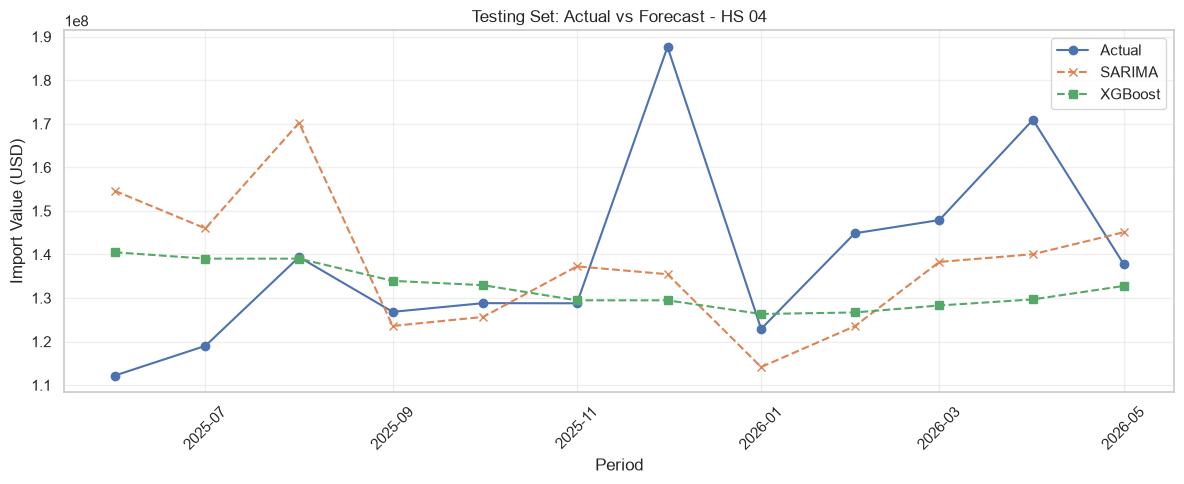

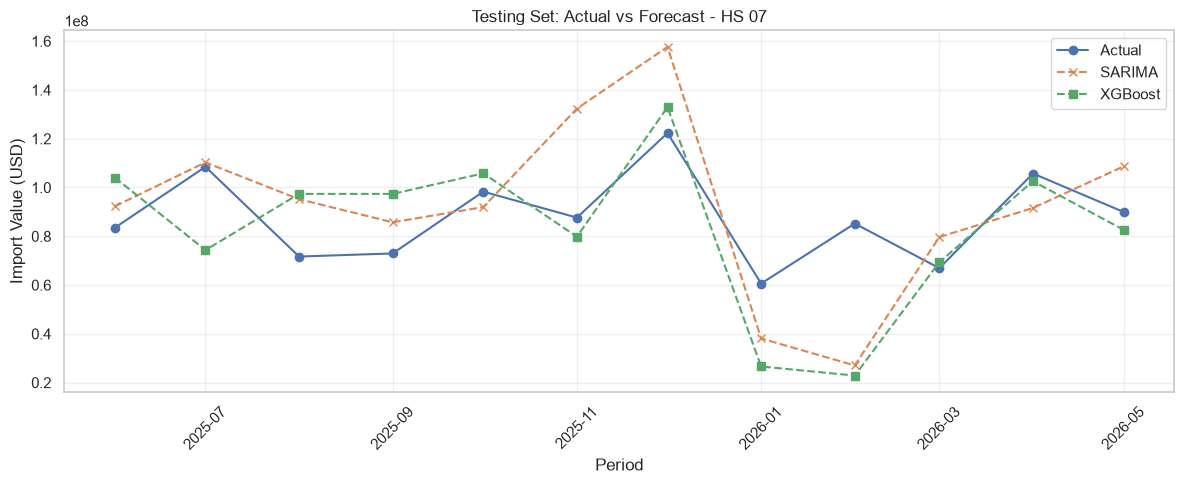

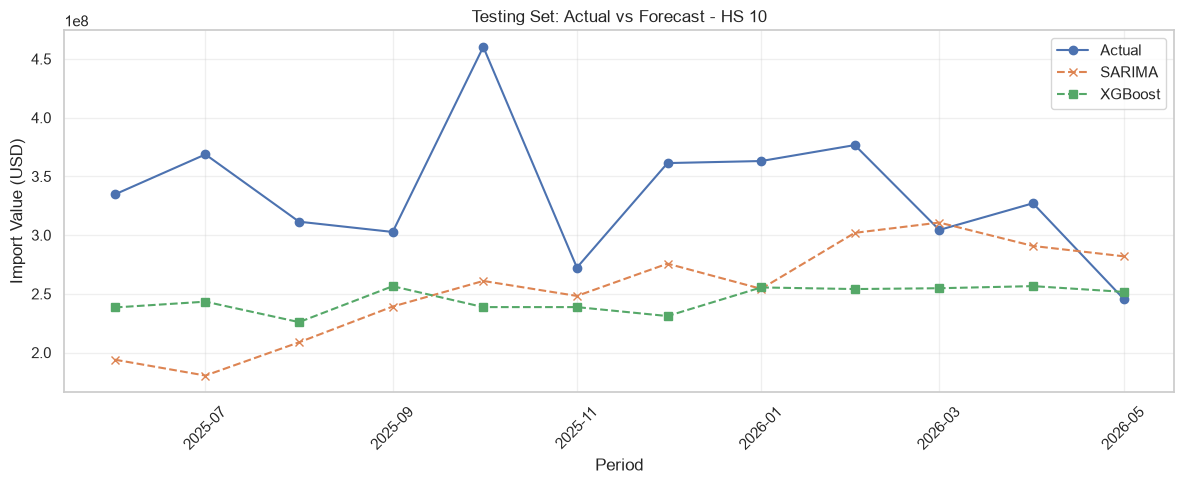

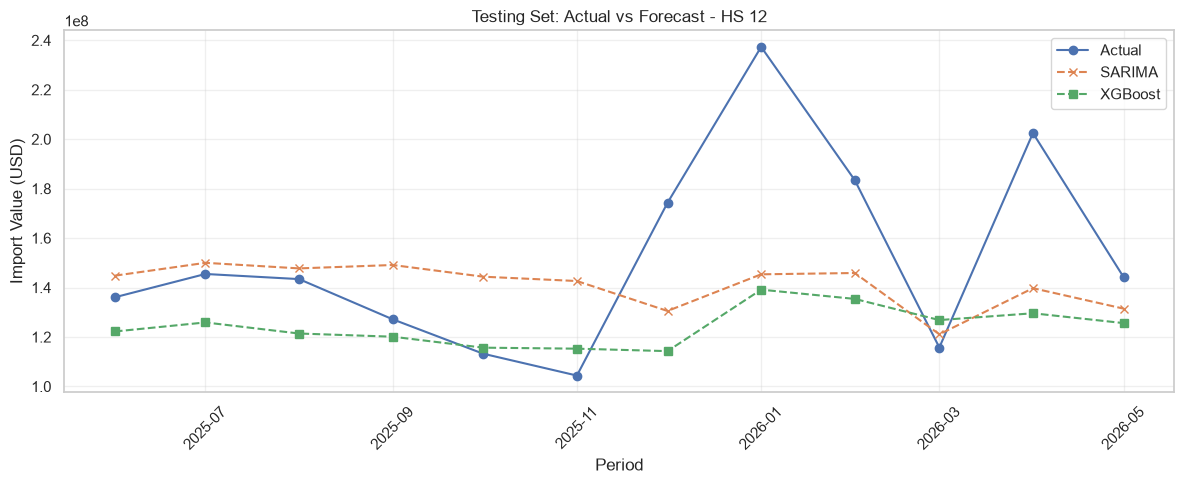

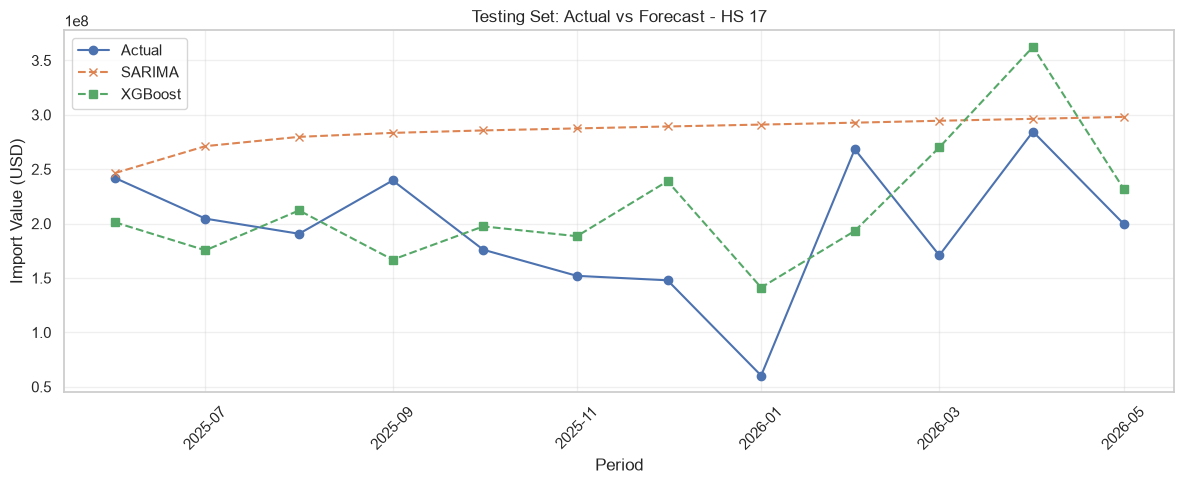

In [423]:
import matplotlib.pyplot as plt

for hs in ['04', '07', '10', '12', '17']:

    data_hs = (
        test_comparison[
            test_comparison['HS_Code'] == hs
        ]
        .sort_values('Period')
    )

    plt.figure(figsize=(12, 5))

    plt.plot(
        data_hs['Period'],
        data_hs['Actual'],
        marker='o',
        label='Actual'
    )

    plt.plot(
        data_hs['Period'],
        data_hs['SARIMA_Prediction'],
        marker='x',
        linestyle='--',
        label='SARIMA'
    )

    plt.plot(
        data_hs['Period'],
        data_hs['XGBoost_Prediction'],
        marker='s',
        linestyle='--',
        label='XGBoost'
    )

    plt.title(f'Testing Set: Actual vs Forecast - HS {hs}')
    plt.xlabel('Period')
    plt.ylabel('Import Value (USD)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [424]:
test_comparison.to_csv(
    'testing_predictions_sarima_xgboost.csv',
    index=False
)

test_metrics.to_csv(
    'testing_metrics_sarima_xgboost.csv',
    index=False
)

print("File hasil evaluasi berhasil disimpan.")

File hasil evaluasi berhasil disimpan.


## Analisis Lanjutan

### Analisis Volatilitas

Menghitung tiga ukuran:
* Standard deviation (SD): besarnya variasi nilai impor dalam satuan aslinya. Berguna untuk melihat variasi absolut, tetapi tidak adil untuk membandingkan komoditas dengan skala nilai berbeda.
* Coefficient of variation (CV): SD dibagi rata-rata. Ini lebih sesuai untuk membandingkan volatilitas relatif antar-HS.
* Month-to-month percentage change: perubahan persentase dari satu bulan ke bulan berikutnya. Ini membantu mengidentifikasi perubahan ekstrem yang mungkin sulit diprediksi.

In [425]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Pastikan data terurut berdasarkan HS dan waktu
volatility_df = train_df.copy()
volatility_df['Period'] = pd.to_datetime(volatility_df['Period'])
volatility_df = volatility_df.sort_values(['HS_Code', 'Period'])

# Hitung perubahan bulanan per HS
volatility_df['MoM_Change'] = (
    volatility_df.groupby('HS_Code')['Import_Value']
    .pct_change() * 100
)

# Hitung indikator volatilitas
volatility_summary = (
    volatility_df.groupby('HS_Code')
    .agg(
        N=('Import_Value', 'count'),
        Mean=('Import_Value', 'mean'),
        SD=('Import_Value', 'std'),
        Min=('Import_Value', 'min'),
        Max=('Import_Value', 'max'),
        Mean_Abs_MoM=(
            'MoM_Change',
            lambda x: x.abs().mean()
        ),
        Median_Abs_MoM=(
            'MoM_Change',
            lambda x: x.abs().median()
        ),
        Max_Abs_MoM=(
            'MoM_Change',
            lambda x: x.abs().max()
        ),
        Changes_Above_30=(
            'MoM_Change',
            lambda x: (x.abs() > 30).sum()
        ),
        Changes_Above_50=(
            'MoM_Change',
            lambda x: (x.abs() > 50).sum()
        )
    )
    .reset_index()
)

# Coefficient of Variation
volatility_summary['CV'] = (
    volatility_summary['SD'] /
    volatility_summary['Mean'] * 100
)

# Format HS Code
volatility_summary['HS_Code'] = (
    volatility_summary['HS_Code']
    .astype(str).str.zfill(2)
)

# Susun kolom
volatility_summary = volatility_summary[
    [
        'HS_Code', 'N', 'Mean', 'SD', 'CV',
        'Mean_Abs_MoM', 'Median_Abs_MoM',
        'Max_Abs_MoM', 'Changes_Above_30',
        'Changes_Above_50'
    ]
]

display(volatility_summary.round(2))


,HS_Code,N,Mean,SD,CV,Mean_Abs_MoM,Median_Abs_MoM,Max_Abs_MoM,Changes_Above_30,Changes_Above_50
0,04,137,1.054566e+08,3.455554e+07,32.77,22.83,18.00,95.74,41,11
1,07,137,6.889660e+07,3.395212e+07,49.28,46.76,30.65,296.05,70,42
2,10,137,3.326337e+08,1.277046e+08,38.39,21.53,18.51,77.75,31,10
3,12,137,1.355928e+08,4.248875e+07,31.34,28.08,18.65,287.65,46,18
4,17,137,2.043723e+08,8.369068e+07,40.95,39.29,28.80,558.26,63,27


In [426]:

extreme_changes = volatility_df.copy()

extreme_changes['HS_Code'] = (
    extreme_changes['HS_Code']
    .astype(str).str.zfill(2)
)

extreme_changes['Abs_MoM'] = (
    extreme_changes['MoM_Change'].abs()
)

extreme_changes = (
    extreme_changes.dropna(subset=['MoM_Change'])
    .sort_values('Abs_MoM', ascending=False)
)

display(
    extreme_changes[
        ['Period', 'HS_Code', 'Import_Value',
         'MoM_Change', 'Abs_MoM']
    ].head(20)
)


,Period,HS_Code,Import_Value,MoM_Change,Abs_MoM
457,2020-02-01,17,2.531008e+08,558.258448,558.258448
554,2023-03-01,07,7.993319e+07,296.045372,296.045372
119,2014-12-01,12,1.115809e+08,287.646439,287.646439
268,2019-05-01,07,9.569580e+07,270.020543,270.020543
156,2015-01-01,17,1.953308e+08,250.604273,250.604273
578,2025-03-01,07,7.639808e+07,239.289613,239.289613
278,2020-03-01,07,5.246940e+07,234.862283,234.862283
445,2019-02-01,17,1.474309e+08,216.883955,216.883955
566,2024-03-01,07,9.025298e+07,196.399140,196.399140
291,2021-04-01,07,8.568359e+07,177.306636,177.306636


### Analisis Perubahan Pola
Menghitung:
* Membandingkan mean dan CV dua subperiode yaitu 2014-2019 dan 2020-2024
* Seasonal Index: menunjukkan rata-rata nilai impor pada suatu bulan dibandingkan dengan rata-rata keseluruhan komoditas pada tahun lengkap 2014-2024
    - Indeks 100 berarti rata-rata bulan tersebut sama dengan rata-rata keseluruhan.
    - Di atas 100 berarti relatif lebih tinggi.
    - Di bawah 100 berarti relatif lebih rendah.
* Korelasi profil bulanan setiap tahun dengan profil bulanan rata-rata, semakin tinggi korelasinya semakin mirip pola bulanan dengan rata-rata historis
    - HS 10 memiliki konsistensi pola musiman paling rendah. Meskipun seasonal index agregatnya relatif datar, profil bulanan dari tahun ke tahun tidak konsisten dengan pola rata-rata historis.
    - HS 17 juga menunjukkan konsistensi musiman yang relatif rendah. Ini dapat menjadi salah satu faktor yang membuat model kesulitan mempelajari pola yang stabil.
    - HS 07 justru memiliki rata-rata korelasi tertinggi, walaupun volatilitasnya tinggi. Ini mengindikasikan bahwa fluktuasi besar pada HS 07 mungkin masih memiliki struktur bulanan yang relatif berulang.

,HS_Code,Period_Group,N,Mean,SD,CV
0,04,2014-2019,72,8.703830e+07,2.408371e+07,27.67
1,04,2020-2024,60,1.249016e+08,3.396630e+07,27.19
2,07,2014-2019,72,5.870936e+07,2.673947e+07,45.55
3,07,2020-2024,60,8.144270e+07,3.792950e+07,46.57
4,10,2014-2019,72,2.765753e+08,6.426782e+07,23.24
5,10,2020-2024,60,4.053435e+08,1.505487e+08,37.14
6,12,2014-2019,72,1.181581e+08,3.192650e+07,27.02
7,12,2020-2024,60,1.566750e+08,4.503802e+07,28.75
8,17,2014-2019,72,1.611048e+08,5.553603e+07,34.47
9,17,2020-2024,60,2.564430e+08,8.337692e+07,32.51


HS_Code,04,07,10,12,17
Month,,,,,
1,71.11,47.38,97.04,107.37,81.49
2,91.55,44.16,103.45,91.15,105.62
3,112.71,80.29,111.42,117.04,126.30
4,111.61,104.53,97.25,126.94,108.62
5,108.89,115.65,101.33,122.56,109.63
6,108.58,122.68,94.27,110.91,106.37
7,79.17,105.22,89.34,95.83,92.94
8,112.24,104.64,95.54,92.18,92.56
9,92.62,93.89,99.79,86.63,87.04


,HS_Code,mean,median,min,max
0,04,0.629,0.657,0.120,0.846
1,07,0.683,0.803,0.158,0.869
2,10,0.261,0.384,-0.368,0.695
3,12,0.597,0.645,0.216,0.871
4,17,0.376,0.533,-0.406,0.726


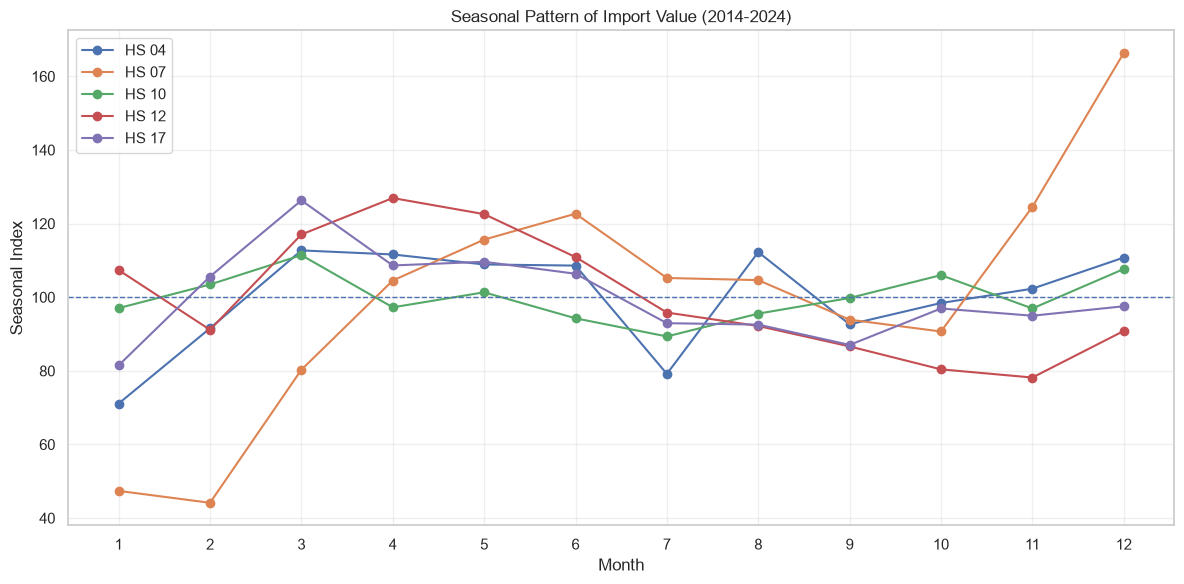

In [427]:

# ============================================
# ANALISIS PERUBAHAN POLA DAN MUSIMAN
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pattern_df = train_df.copy()

pattern_df['Period'] = pd.to_datetime(pattern_df['Period'])
pattern_df['HS_Code'] = (
    pattern_df['HS_Code'].astype(str).str.zfill(2)
)

pattern_df = pattern_df.sort_values(['HS_Code', 'Period'])

pattern_df['Year'] = pattern_df['Period'].dt.year
pattern_df['Month'] = pattern_df['Period'].dt.month

# Gunakan tahun lengkap untuk analisis musiman
complete_years = pattern_df[
    pattern_df['Year'] <= 2024
].copy()

# --------------------------------------------
# A. Perbandingan subperiode
# --------------------------------------------

period_data = []

for hs, group in complete_years.groupby('HS_Code'):

    for label, start, end in [
        ('2014-2019', 2014, 2019),
        ('2020-2024', 2020, 2024)
    ]:

        values = group.loc[
            group['Year'].between(start, end),
            'Import_Value'
        ]

        period_data.append({
            'HS_Code': hs,
            'Period_Group': label,
            'N': len(values),
            'Mean': values.mean(),
            'SD': values.std(),
            'CV': values.std() / values.mean() * 100
        })

period_comparison = pd.DataFrame(period_data)

display(period_comparison.round(2))


# --------------------------------------------
# B. Seasonal index
# --------------------------------------------

monthly_mean = (
    complete_years.groupby(['HS_Code', 'Month'])
    ['Import_Value'].mean()
    .reset_index(name='Monthly_Mean')
)

overall_mean = (
    complete_years.groupby('HS_Code')['Import_Value']
    .mean()
    .rename('Overall_Mean')
)

monthly_mean = monthly_mean.merge(
    overall_mean,
    on='HS_Code'
)

monthly_mean['Seasonal_Index'] = (
    monthly_mean['Monthly_Mean'] /
    monthly_mean['Overall_Mean'] * 100
)

seasonal_pivot = monthly_mean.pivot(
    index='Month',
    columns='HS_Code',
    values='Seasonal_Index'
)

display(seasonal_pivot.round(2))


# --------------------------------------------
# C. Konsistensi profil bulanan antar-tahun
# --------------------------------------------

annual_monthly = (
    complete_years.groupby(['HS_Code', 'Year', 'Month'])
    ['Import_Value'].mean()
    .reset_index()
)

consistency_results = []

for hs, group in annual_monthly.groupby('HS_Code'):

    reference_profile = (
        group.groupby('Month')['Import_Value'].mean()
    )

    for year, year_group in group.groupby('Year'):

        yearly_profile = (
            year_group.set_index('Month')['Import_Value']
        )

        common_months = yearly_profile.index.intersection(
            reference_profile.index
        )

        correlation = yearly_profile.loc[common_months].corr(
            reference_profile.loc[common_months]
        )

        consistency_results.append({
            'HS_Code': hs,
            'Year': year,
            'Profile_Correlation': correlation
        })

consistency_df = pd.DataFrame(consistency_results)

consistency_summary = (
    consistency_df.groupby('HS_Code')['Profile_Correlation']
    .agg(['mean', 'median', 'min', 'max'])
    .reset_index()
)

display(consistency_summary.round(3))


# --------------------------------------------
# D. Plot seasonal index
# --------------------------------------------

plt.figure(figsize=(12, 6))

for hs in sorted(seasonal_pivot.columns):
    plt.plot(
        seasonal_pivot.index,
        seasonal_pivot[hs],
        marker='o',
        label=f'HS {hs}'
    )

plt.axhline(100, linestyle='--', linewidth=1)
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Seasonal Index')
plt.title('Seasonal Pattern of Import Value (2014-2024)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Analisis residual dan error
* Pola overforecast/underforecast
    - Residual = Prediksi - Aktual
    - Nilai positif overforecast
    - Nilai negative underforecast
* Membandingkan absolute percentage error per bulan
* Analisis bias relatif dan besarnya kesalahan
    - Bias: apakah model secara konsisten memprediksi terlalu tinggi atau terlalu rendah?
    - Error magnitude: seberapa besar jarak prediksi dari nilai aktual?

,HS_Code,Model,Mean_Error,Mean_Absolute_Error,Mean_APE,Overforecast,Underforecast,Max_APE,Month_Max_APE
0,04,SARIMA,-1101101.40,20422825.81,14.47,5,7,37.80,2025-06
1,04,XGBoost,-6579784.04,17191529.14,11.59,6,6,31.00,2025-12
2,07,SARIMA,4763493.66,21623377.55,25.62,8,4,68.28,2026-02
3,07,XGBoost,-4796709.53,20002494.67,24.56,6,6,73.15,2026-02
4,10,SARIMA,-81801147.54,88874323.61,25.05,2,10,51.07,2025-07
5,10,XGBoost,-90266850.67,91241202.67,25.37,1,11,48.14,2025-10
6,12,SARIMA,-11209934.18,30250761.93,18.56,7,5,38.75,2026-01
7,12,XGBoost,-27976436.93,32046427.10,18.13,3,9,41.37,2026-01
8,17,SARIMA,89930440.47,89930440.47,71.98,12,0,382.55,2026-01
9,17,XGBoost,20244453.38,56540897.93,36.19,8,4,134.18,2026-01


,Period,HS_Code,Actual,SARIMA_Error,SARIMA_APE,XGBoost_Error,XGBoost_APE
0,2025-06-01,04,1.121982e+08,4.241143e+07,37.80,2.830413e+07,25.23
1,2025-07-01,04,1.190203e+08,2.695326e+07,22.65,2.001789e+07,16.82
2,2025-08-01,04,1.394032e+08,3.082028e+07,22.11,-3.649319e+05,0.26
3,2025-09-01,04,1.268274e+08,-3.241374e+06,2.56,7.116098e+06,5.61
4,2025-10-01,04,1.288244e+08,-3.153142e+06,2.45,4.119850e+06,3.20
5,2025-11-01,04,1.287884e+08,8.479727e+06,6.58,6.832411e+05,0.53
6,2025-12-01,04,1.876536e+08,-5.218834e+07,27.81,-5.818199e+07,31.00
7,2026-01-01,04,1.229084e+08,-8.756158e+06,7.12,3.429258e+06,2.79
8,2026-02-01,04,1.448597e+08,-2.133080e+07,14.73,-1.817559e+07,12.55
9,2026-03-01,04,1.478987e+08,-9.615373e+06,6.50,-1.961364e+07,13.26


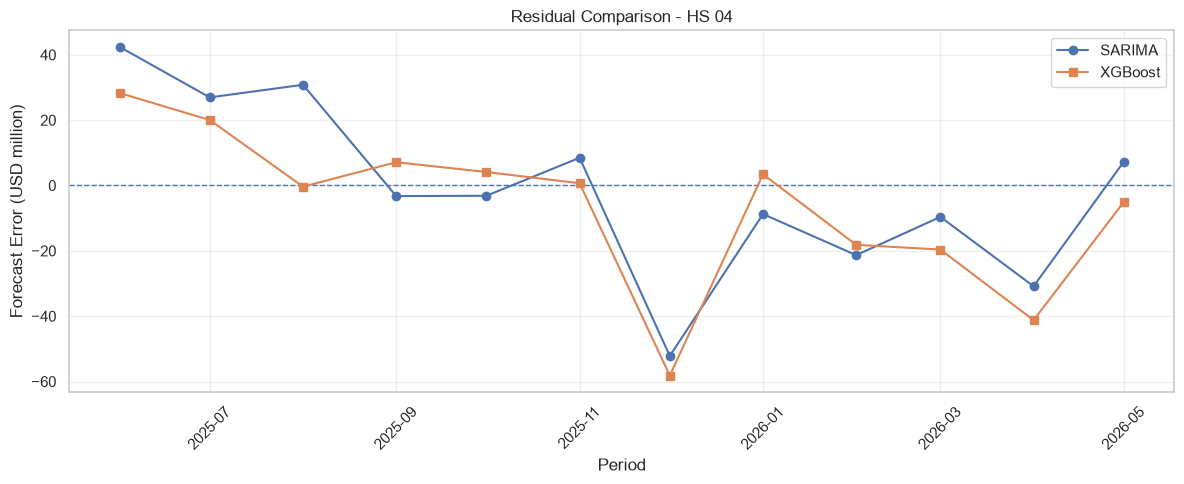

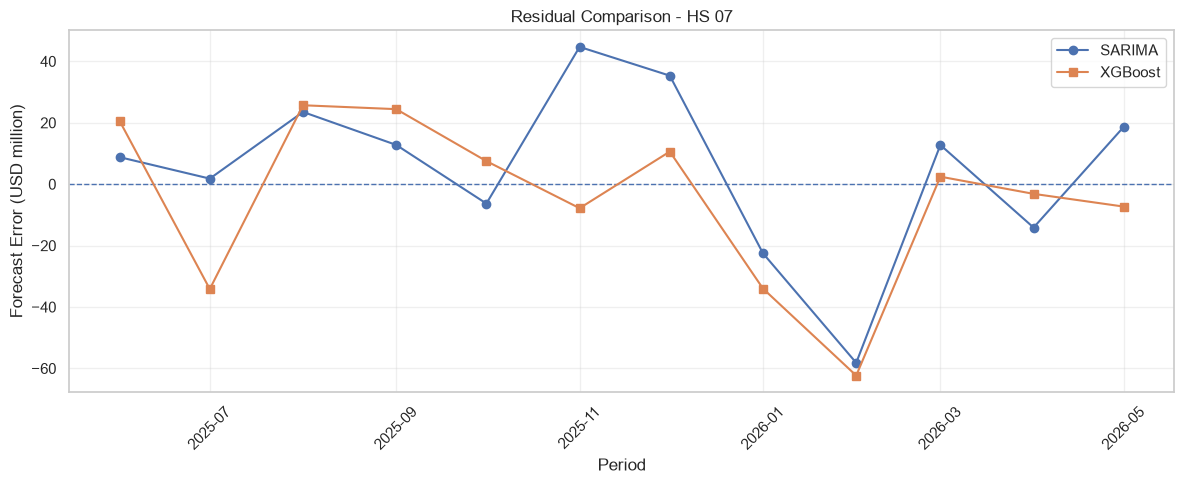

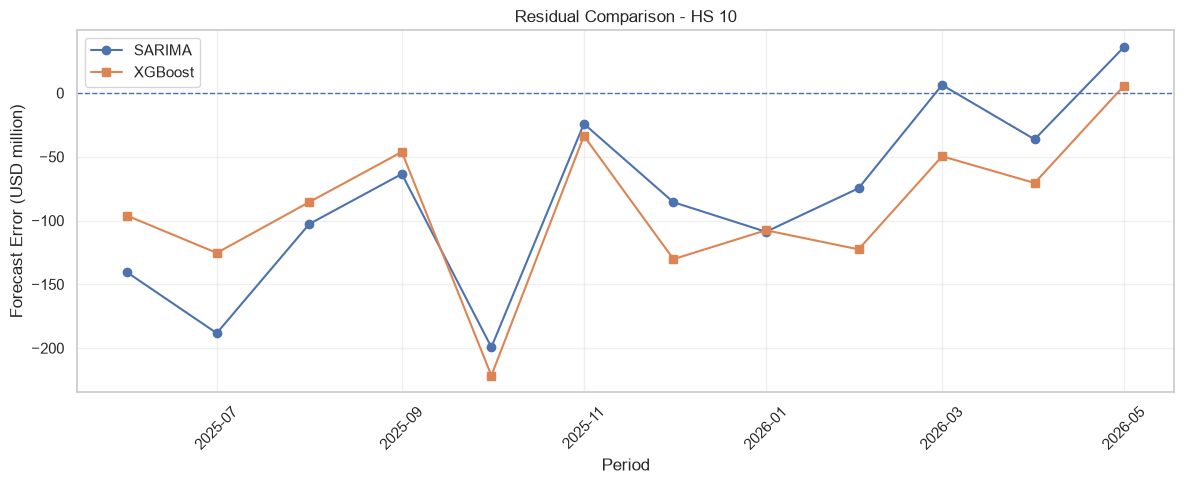

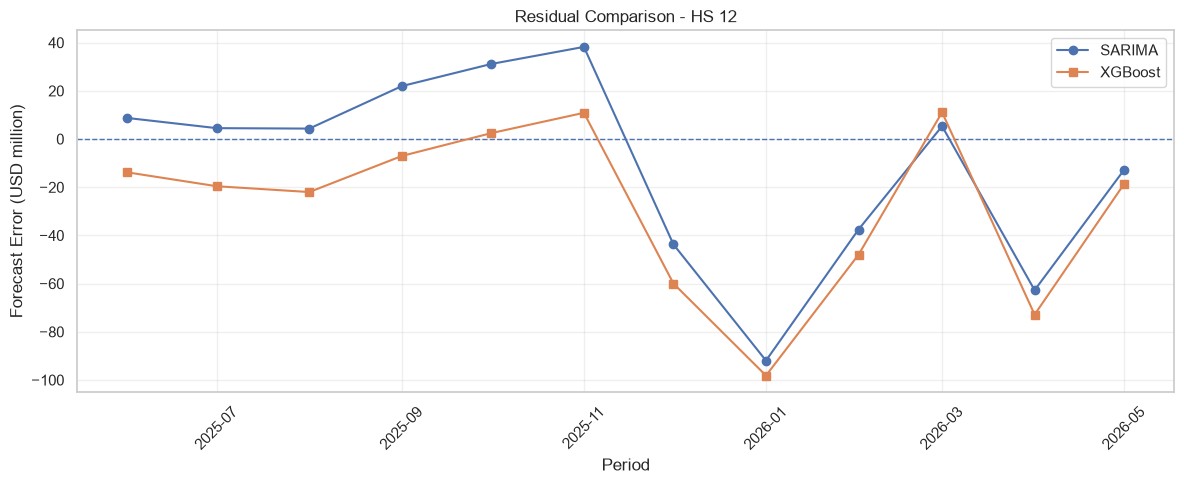

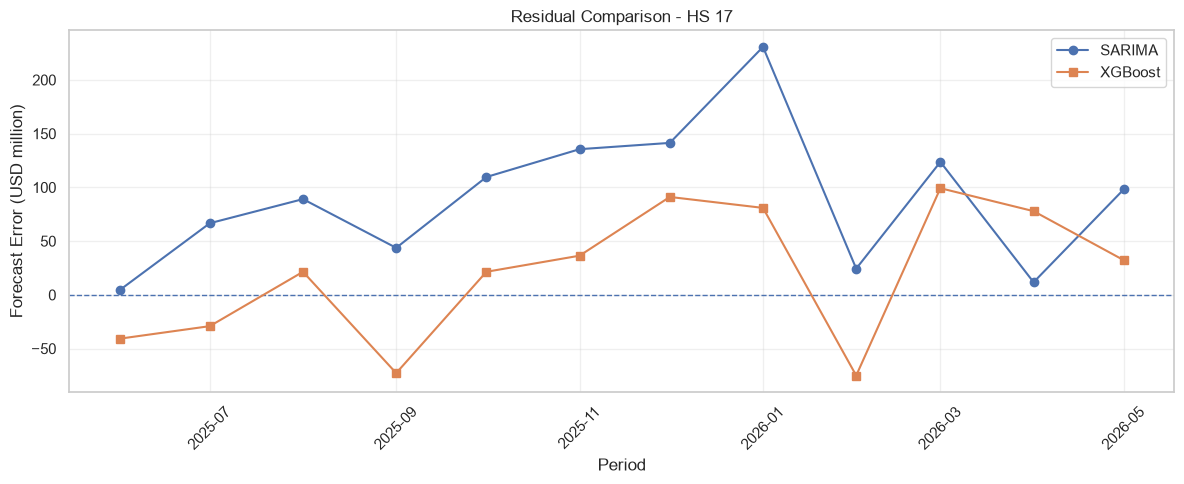

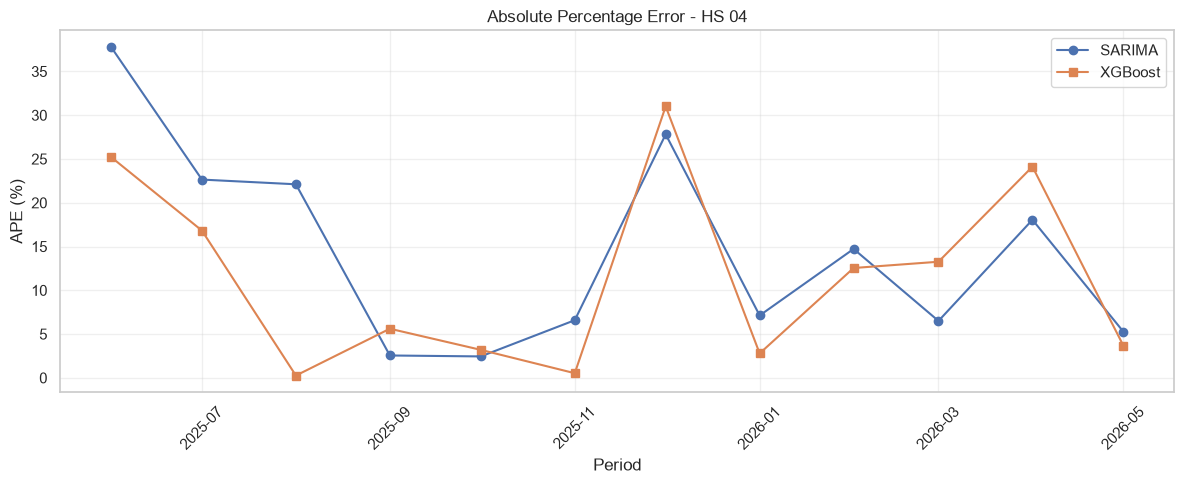

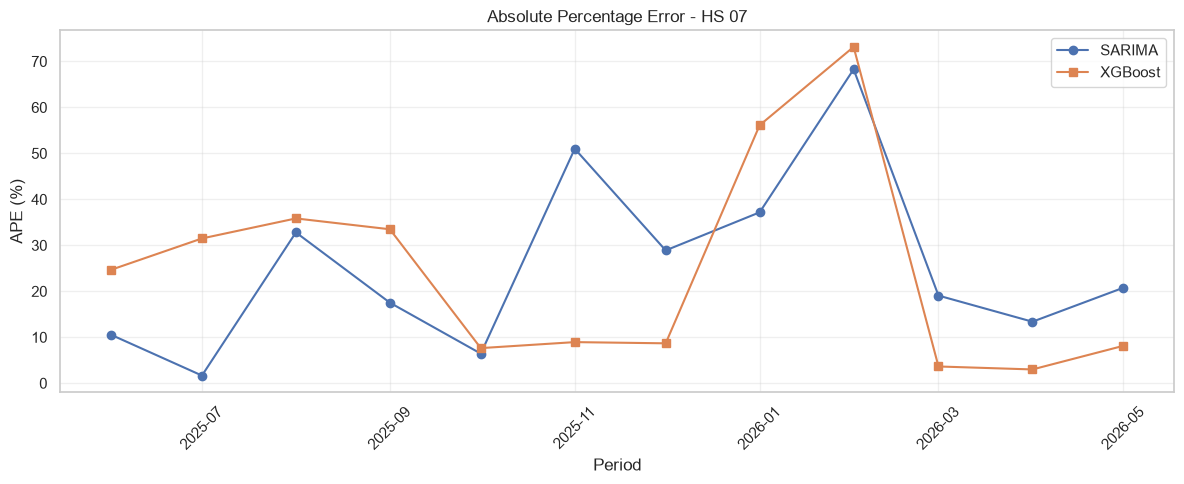

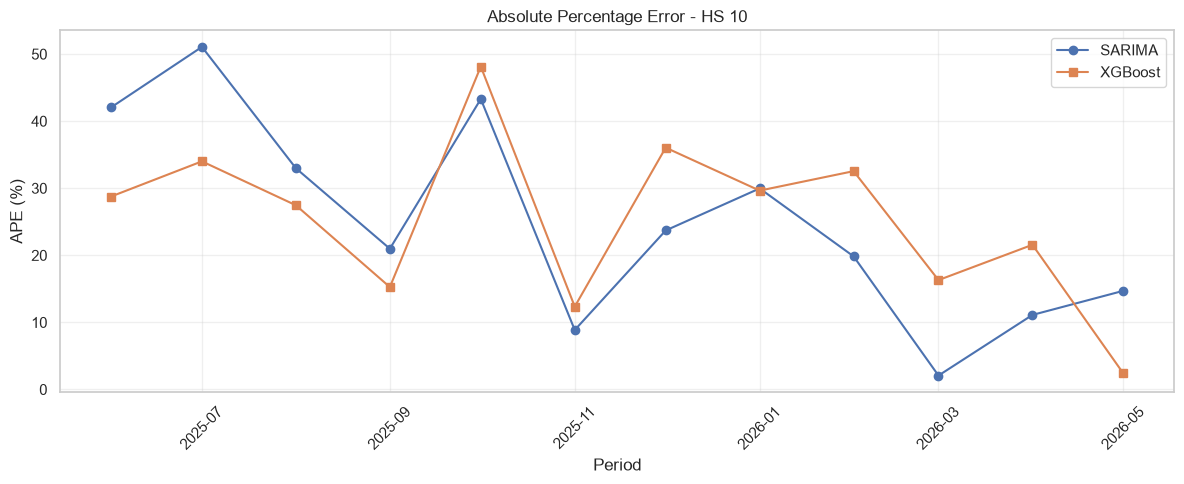

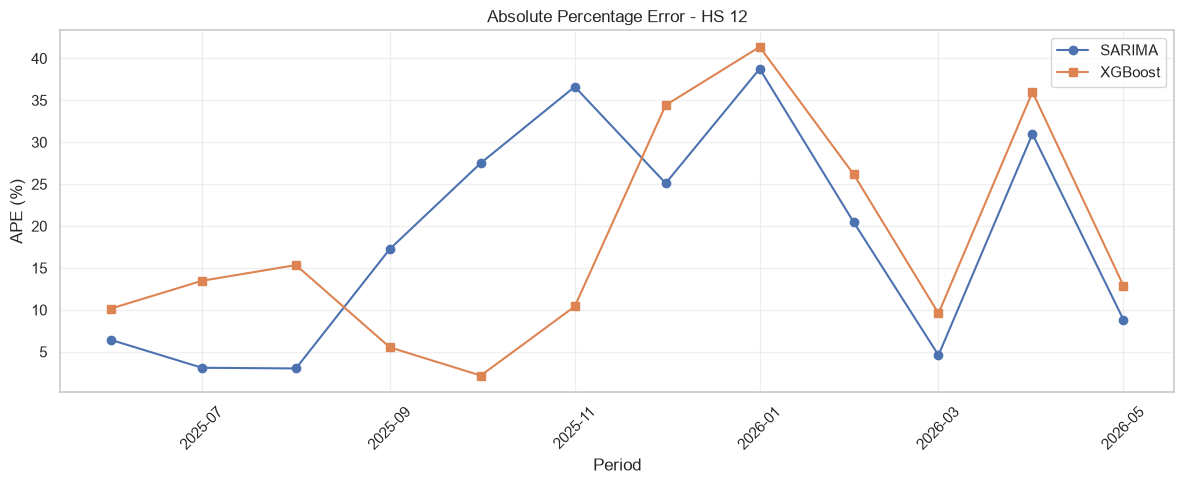

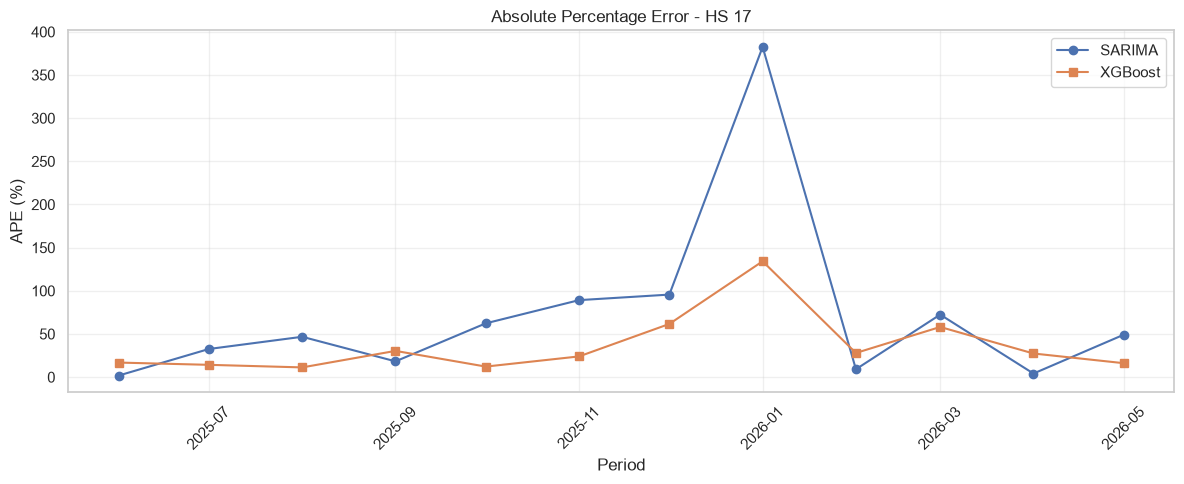

In [428]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Salin agar objek utama tidak berubah
error_df = test_comparison.copy()

error_df['Period'] = pd.to_datetime(error_df['Period'])
error_df['HS_Code'] = (
    error_df['HS_Code'].astype(str).str.zfill(2)
)

# Pastikan urutan waktu
error_df = error_df.sort_values(['HS_Code', 'Period'])

# ---------------------------------------
# A. Hitung residual dan absolute error
# ---------------------------------------

for model in ['SARIMA', 'XGBoost']:

    pred_col = f'{model}_Prediction'

    error_df[f'{model}_Error'] = (
        error_df[pred_col] - error_df['Actual']
    )

    error_df[f'{model}_AbsError'] = (
        error_df[f'{model}_Error'].abs()
    )

    error_df[f'{model}_APE'] = (
        error_df[f'{model}_AbsError'] /
        error_df['Actual'] * 100
    )

    error_df[f'{model}_BiasPct'] = (
        error_df[f'{model}_Error'] /
        error_df['Actual'] * 100
    )


# ---------------------------------------
# B. Ringkasan bias dan error per HS
# ---------------------------------------

summary = []

for hs, group in error_df.groupby('HS_Code'):

    for model in ['SARIMA', 'XGBoost']:

        error = group[f'{model}_Error']
        ape = group[f'{model}_APE']

        summary.append({
            'HS_Code': hs,
            'Model': model,
            'Mean_Error': error.mean(),
            'Mean_Absolute_Error': error.abs().mean(),
            'Mean_APE': ape.mean(),
            'Overforecast': (error > 0).sum(),
            'Underforecast': (error < 0).sum(),
            'Max_APE': ape.max(),
            'Month_Max_APE': group.loc[
                ape.idxmax(), 'Period'
            ].strftime('%Y-%m')
        })

error_summary = pd.DataFrame(summary)

display(error_summary.round(2))


# ---------------------------------------
# C. Tabel error per bulan
# ---------------------------------------

monthly_error = error_df[
    [
        'Period', 'HS_Code', 'Actual',
        'SARIMA_Error', 'SARIMA_APE',
        'XGBoost_Error', 'XGBoost_APE'
    ]
].copy()

display(monthly_error.round(2))


# ---------------------------------------
# D. Grafik residual per HS
# ---------------------------------------

hs_codes = sorted(error_df['HS_Code'].unique())

for hs in hs_codes:

    group = error_df[
        error_df['HS_Code'] == hs
    ].copy()

    plt.figure(figsize=(12, 5))

    plt.axhline(
        0, linestyle='--', linewidth=1
    )

    plt.plot(
        group['Period'],
        group['SARIMA_Error'] / 1e6,
        marker='o',
        label='SARIMA'
    )

    plt.plot(
        group['Period'],
        group['XGBoost_Error'] / 1e6,
        marker='s',
        label='XGBoost'
    )

    plt.title(f'Residual Comparison - HS {hs}')
    plt.xlabel('Period')
    plt.ylabel('Forecast Error (USD million)')
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ---------------------------------------
# E. Grafik APE per HS
# ---------------------------------------

for hs in hs_codes:

    group = error_df[
        error_df['HS_Code'] == hs
    ].copy()

    plt.figure(figsize=(12, 5))

    plt.plot(
        group['Period'],
        group['SARIMA_APE'],
        marker='o',
        label='SARIMA'
    )

    plt.plot(
        group['Period'],
        group['XGBoost_APE'],
        marker='s',
        label='XGBoost'
    )

    plt.title(f'Absolute Percentage Error - HS {hs}')
    plt.xlabel('Period')
    plt.ylabel('APE (%)')
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [429]:

import pandas as pd
import numpy as np

# Gunakan development training saja
feature_diag = train_df.copy()

feature_diag['Period'] = pd.to_datetime(feature_diag['Period'])
feature_diag['HS_Code'] = (
    feature_diag['HS_Code'].astype(str).str.zfill(2)
)

feature_diag = feature_diag.sort_values(
    ['HS_Code', 'Period']
).copy()

# Pastikan nilai positif sebelum log
assert (feature_diag['Import_Value'] > 0).all()

feature_diag['log_y'] = np.log(feature_diag['Import_Value'])

# Bangun fitur yang digunakan XGBoost
for lag in [1, 12]:
    feature_diag[f'lag_{lag}'] = (
        feature_diag.groupby('HS_Code')['log_y'].shift(lag)
    )

feature_diag['rolling_mean_3'] = (
    feature_diag.groupby('HS_Code')['log_y']
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

feature_diag['rolling_std_3'] = (
    feature_diag.groupby('HS_Code')['log_y']
    .transform(lambda x: x.shift(1).rolling(3).std())
)

feature_diag['month'] = feature_diag['Period'].dt.month

# -----------------------------------------
# A. Korelasi target dengan fitur historis
# -----------------------------------------

feature_corr_rows = []

for hs, group in feature_diag.groupby('HS_Code'):

    usable = group.dropna(
        subset=[
            'log_y', 'lag_1', 'lag_12',
            'rolling_mean_3', 'rolling_std_3'
        ]
    )

    for feature in [
        'lag_1', 'lag_12',
        'rolling_mean_3', 'rolling_std_3'
    ]:
        feature_corr_rows.append({
            'HS_Code': hs,
            'Feature': feature,
            'Correlation_with_Current_Log_Value':
                usable['log_y'].corr(usable[feature])
        })

feature_corr = pd.DataFrame(feature_corr_rows)

display(
    feature_corr.pivot(
        index='HS_Code',
        columns='Feature',
        values='Correlation_with_Current_Log_Value'
    ).round(3)
)


# -----------------------------------------
# B. Autokorelasi seri log nilai impor
# -----------------------------------------

acf_rows = []

for hs, group in feature_diag.groupby('HS_Code'):

    y = group['log_y'].dropna()

    for lag in [1, 3, 6, 12]:
        acf_rows.append({
            'HS_Code': hs,
            'Lag': lag,
            'Autocorrelation': y.autocorr(lag=lag)
        })

acf_summary = pd.DataFrame(acf_rows)

display(
    acf_summary.pivot(
        index='HS_Code',
        columns='Lag',
        values='Autocorrelation'
    ).round(3)
)


# -----------------------------------------
# C. Ketersediaan fitur setelah lagging
# -----------------------------------------

feature_availability = []

for hs, group in feature_diag.groupby('HS_Code'):

    feature_availability.append({
        'HS_Code': hs,
        'Original_Observations': len(group),
        'Rows_Available_After_Feature_Engineering':
            group.dropna(
                subset=[
                    'lag_1', 'lag_12',
                    'rolling_mean_3', 'rolling_std_3'
                ]
            ).shape[0],
        'Rows_Lost':
            group[
                [
                    'lag_1', 'lag_12',
                    'rolling_mean_3', 'rolling_std_3'
                ]
            ].isna().any(axis=1).sum()
    })

display(pd.DataFrame(feature_availability))


Feature,lag_1,lag_12,rolling_mean_3,rolling_std_3
HS_Code,,,,
04,0.603,0.621,0.673,-0.115
07,0.349,0.651,0.029,-0.266
10,0.720,0.320,0.712,0.072
12,0.432,0.479,0.483,-0.025
17,0.448,0.490,0.453,-0.018


Lag,1,3,6,12
HS_Code,,,,
04,0.591,0.523,0.696,0.621
07,0.351,-0.142,0.123,0.651
10,0.715,0.528,0.486,0.320
12,0.444,0.276,0.014,0.479
17,0.482,0.313,0.294,0.490


,HS_Code,Original_Observations,Rows_Available_After_Feature_Engineering,Rows_Lost
0,04,137,125,12
1,07,137,125,12
2,10,137,125,12
3,12,137,125,12
4,17,137,125,12
